In [2]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
from bioframe import overlap
#import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
import gzip
from numpy import diff
from scipy import signal
import scipy.ndimage
from matplotlib.ticker import EngFormatter
from scipy.stats import pearsonr
import polars as pl

In [64]:
# H1 stages 
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0403/droplethic_merged_dedup_sorted.pairs"

#DE stages
file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/DE/droplethic_merged_dedup_sorted.pairs"

#HB stages
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/HB/droplethic_merged_dedup_sorted.pairs"

#iHep stages 
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/iHep/droplethic_merged_dedup_sorted.pairs"

# mHep stages (too large use polar)
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0919/droplethic_merged_dedup_sorted.pairs"

# Scan (lazy, streaming)
df = pl.scan_csv(
    file_path,
    separator="\t",
    comment_char="#",
    has_header=False,
    quote_char='"',
    null_values=["null"]
)

# Assign column names
df = df.rename({
    "column_1": "readID", "column_2": "chrom1", "column_3": "pos1",
    "column_4": "chrom2", "column_5": "pos2", "column_6": "strand1",
    "column_7": "strand2", "column_8": "pair_type", "column_9": "mapq1",
    "column_10": "mapq2", "column_11": "BX1", "column_12": "BX2"
})


# Count cis and trans directly (no full materialization)
cis_trans = (
    df.with_columns((pl.col("chrom1") == pl.col("chrom2")).alias("is_cis"))
      .groupby("is_cis")
      .count()
      .collect(streaming=True)   # run in streaming mode
)

cis_contacts = cis_trans.filter(pl.col("is_cis") == True)["count"][0]
trans_contacts = cis_trans.filter(pl.col("is_cis") == False)["count"][0]

cis_ratio = cis_contacts / (cis_contacts + trans_contacts)

print(f"Cis contacts: {cis_contacts}")
print(f"Trans contacts: {trans_contacts}")
print(f"Cis ratio: {cis_ratio:.4f}")

Cis contacts: 755361760
Trans contacts: 94740174
Cis ratio: 0.8886


In [65]:
#filter the interactions on diagnal.

# Filter by pair_type == "UU"
df = df.filter(pl.col("pair_type") == "UU")

# Filter contacts < 1kb
df_larger1kb = df.filter(
        ~(
            (pl.col("chrom1") == pl.col("chrom2"))
            & ((pl.col("pos1") - pl.col("pos2")).abs() < 400)
        )
    )

# Define output path
#out_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0403/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
out_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/DE/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#out_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/HB/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#out_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/iHep/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#out_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0919/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"

# Save using sink_csv (streaming, best for large files)
df_larger1kb.sink_csv(out_path, separator="\t")

# Count cis and trans directly (no full materialization)
cis_trans = (
    df_larger1kb.with_columns((pl.col("chrom1") == pl.col("chrom2")).alias("is_cis"))
      .groupby("is_cis")
      .count()
      .collect(streaming=True)   # run in streaming mode
)

cis_contacts = cis_trans.filter(pl.col("is_cis") == True)["count"][0]
trans_contacts = cis_trans.filter(pl.col("is_cis") == False)["count"][0]

cis_ratio = cis_contacts / (cis_contacts + trans_contacts)

print(f"filtered Cis contacts: {cis_contacts}")
print(f"filtered Trans contacts: {trans_contacts}")
print(f"filtered Cis ratio: {cis_ratio:.4f}")

filtered Cis contacts: 19843635
filtered Trans contacts: 17804583
filtered Cis ratio: 0.5271


# plot the pseudobulk scalling plot

In [12]:
# === 1. Fetch hg38 chromosome sizes, centromeres, and arms ===
hg38_chromsizes = bf.fetch_chromsizes("hg38")
hg38_cens = bf.fetch_centromeres("hg38")
hg38_arms = bf.make_chromarms(hg38_chromsizes, hg38_cens)
hg38_arms["arm"] = hg38_arms["name"].str.split("_").str[1]
canonical_chroms = list(set(hg38_arms["chrom"]))

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amin at 0x1517780bfec0> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amax at 0x1517780bfce0> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()


Cis contacts: 11,155,299
Sampled 30,000 rows for plotting


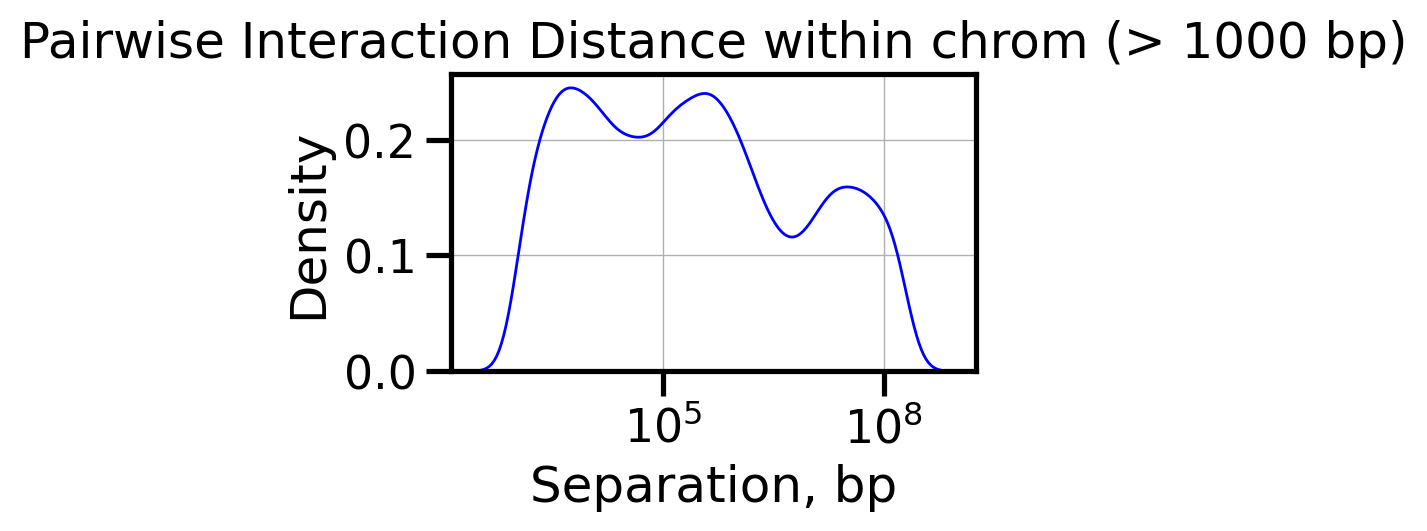

In [54]:
# === 3. Build cis filtering pipeline ===
df_cis = (
    df.filter(pl.col("chrom1") == pl.col("chrom2"))
      .filter(pl.col("chrom1").is_in(canonical_chroms))
      .with_columns((pl.col("pos1") - pl.col("pos2")).abs().alias("Abs_Dist"))
      .filter(pl.col("Abs_Dist") > 1000)
)

# === 4. Count cis contacts (streaming, low memory) ===
cis_contacts = df_cis.select(pl.count()).collect(streaming=True)[0, 0]
print(f"Cis contacts: {cis_contacts:,}")

# === 5. Collect a ~1M row random sample in chunks ===
# Polars LazyFrame doesn’t support sample_frac, so we sample per batch
target = 1_000_000
samples = []
batch_size = 5_000_000  # adjust depending on your node memory

for batch in df_cis.collect(streaming=True).iter_slices(batch_size):
    if batch.height > 0:
        take_n = min(10_000, batch.height)  # sample per batch
        samples.append(batch.sample(n=take_n))
    if sum(s.height for s in samples) >= target:
        break

df_sample = pl.concat(samples)
print(f"Sampled {df_sample.height:,} rows for plotting")

# === 6. Plot KDE from the sample ===
plt.figure(figsize=(4, 3), dpi=200)
sns.kdeplot(
    data=df_sample.to_pandas(),
    x="Abs_Dist",
    lw=1,
    log_scale=True,
    color="blue"
)
plt.xlabel("Separation, bp")
plt.ylabel("Density")
plt.title("Pairwise Interaction Distance within chrom (> 1000 bp)")
plt.grid(lw=0.5)
plt.tight_layout()
plt.show()

In [ ]:
#plot heatmap

In [6]:
import bioframe, cooler
from matplotlib import colors
from scipy.sparse import coo_matrix

def get_pixels(df, binsize, cond):
    chromsizes = bioframe.fetch_chromsizes("hg38")
    bins = cooler.binnify(chromsizes, binsize)
    bins = bins.reset_index().rename(columns={"index":"name"})
    
    binned_df = bioframe.assign_view(
        df.sort_values(["qname","qstart"]),
        bins,
        drop_unassigned=False,
        df_view_col="bin_id",
        view_name_col="name",
        cols=None
    ).dropna(axis=0,how='any')
    
    _pixels = pd.merge(
        binned_df.iloc[:-1].reset_index(drop=True),
        binned_df.iloc[1:].reset_index(drop=True),
        left_index=True,
        right_index=True,
        suffixes=('1','2')
    )[["qname1","qstart1","qend1","strand1","chrom1","start1","end1",
       "qname2","qstart2","qend2","strand2","chrom2","start2","end2",
       "bin_id1","bin_id2"]]

    _from_same_read = (_pixels["qname1"]==_pixels["qname2"])
    _are_consequtive = (_pixels["qend1"]==_pixels["qstart2"]).abs() < 1000000
    almost_pixels = _pixels[_from_same_read & _are_consequtive].drop("qname2", axis=1).reset_index(drop=True)
    print(cond, "| direct interactions (gap<100):", len(almost_pixels))
    
    flip_mask = (almost_pixels["bin_id1"] > almost_pixels["bin_id2"]).values
    almost_pixels.loc[flip_mask, ["bin_id1","bin_id2"]] = (
        almost_pixels.loc[flip_mask, ["bin_id2","bin_id1"]].values
    )
    almost_pixels = almost_pixels.groupby(["bin_id1","bin_id2"]).size().reset_index(
        name="count").rename(columns={"bin_id1":"bin1_id","bin_id2":"bin2_id"})
    
    chrom_pixels = cooler.annotate(almost_pixels, bins[["chrom"]])
    trans = chrom_pixels["count"][chrom_pixels["chrom1"]!=chrom_pixels["chrom2"]].sum()
    cis   = chrom_pixels["count"][chrom_pixels["chrom1"]==chrom_pixels["chrom2"]].sum()
    diag  = chrom_pixels["count"][chrom_pixels["bin1_id"]==chrom_pixels["bin2_id"]].sum()
    total = chrom_pixels["count"].sum()
    print("count trans/cis/diag/total",  ":", trans, cis, diag, total)
    
    N = len(bins)
    mat = coo_matrix((almost_pixels["count"], (almost_pixels["bin1_id"], almost_pixels["bin2_id"])),
                     shape=(N,N)).toarray()
    mat = mat + mat.T
    print(f"generated symmetric matrix {N}×{N}")
    return mat

In [7]:
def pairs_to_bedlike(pairs_df):
    bed1 = pd.DataFrame({
        "qname" : pairs_df["readID"],
        "qstart": pairs_df["pos1"] - 1,
        "qend"  : pairs_df["pos1"],
        "strand": pairs_df["strand1"],
        "chrom" : pairs_df["chrom1"],
        "start" : pairs_df["pos1"] - 1,
        "end"   : pairs_df["pos1"],
    })
    bed2 = pd.DataFrame({
        "qname" : pairs_df["readID"],
        "qstart": pairs_df["pos2"] - 1,
        "qend"  : pairs_df["pos2"],
        "strand": pairs_df["strand2"],
        "chrom" : pairs_df["chrom2"],
        "start" : pairs_df["pos2"] - 1,
        "end"   : pairs_df["pos2"],
    })
    return pd.concat([bed1, bed2], ignore_index=True)

In [66]:
# --- Step 1. Start from Polars DataFrame
pairs_df = df_larger1kb  # if df is LazyFrame already, no need to clone

filtered_pl = (
    pairs_df
    .filter(
        ~(
            (pl.col("chrom1") == pl.col("chrom2"))
            & ((pl.col("pos1") - pl.col("pos2")).abs() < 1000)
        )
    )
)

# Collect lazily -> eager Polars -> convert to pandas
filtered_df = filtered_pl.collect(streaming=True).to_pandas()

In [9]:
# --- Step 4. Use existing pandas-based functions
bed_df = pairs_to_bedlike(filtered_df)

BIN_SIZE = 10_000_000
mat = get_pixels(bed_df, binsize=BIN_SIZE, cond="all")

all | direct interactions (gap<100): 12301278
count trans/cis/diag/total : 8584017 3717261 2687479 12301278
generated symmetric matrix 323×323


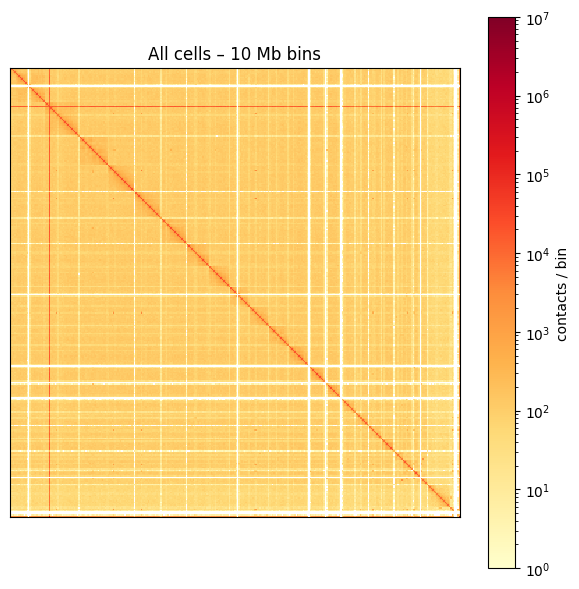

In [ ]:
#plot data 
fig, ax = plt.subplots(figsize=(6, 6), tight_layout=True)

img = ax.imshow(
    mat,
    interpolation="none",
    cmap="YlOrRd",  # same as reference
    norm=colors.LogNorm(vmin=1, vmax=10000000),  # match reference scale
#    origin="upper“  # optional, flip if needed
)

# Add colorbar with label
cbar = plt.colorbar(img, ax=ax)
cbar.set_label("contacts / bin")

# Optional: add title
ax.set_title(f"All cells – {BIN_SIZE//1_000_000} Mb bins")
ax.set_xticks([]); ax.set_yticks([])

plt.show()

# check the single-cell statistics

In [55]:
# count unique BX1 barcodes
n_bx1 = df.select(pl.col("BX1").n_unique()).collect().item()
print(f"Unique BX1 barcodes: {n_bx1}")

Unique BX1 barcodes: 8950106


In [59]:
# Step 1. Compute counts per BX1
counts = df.group_by("BX1").agg(pl.count().alias("cnt"))

# Step 2. Join counts back to df
df_with_counts = df.join(counts, on="BX1")

# Step 3. Filter for BX1 appearing more than 20,000 times
filtered_df = df_with_counts.filter(pl.col("cnt") > 20_000)

# Step 4. Count unique BX1s
n_bx1 = filtered_df.select(pl.col("BX1").n_unique()).collect().item()

print(f"Number of BX1 with >20,000 counts: {n_bx1}")

Number of BX1 with >20,000 counts: 3970


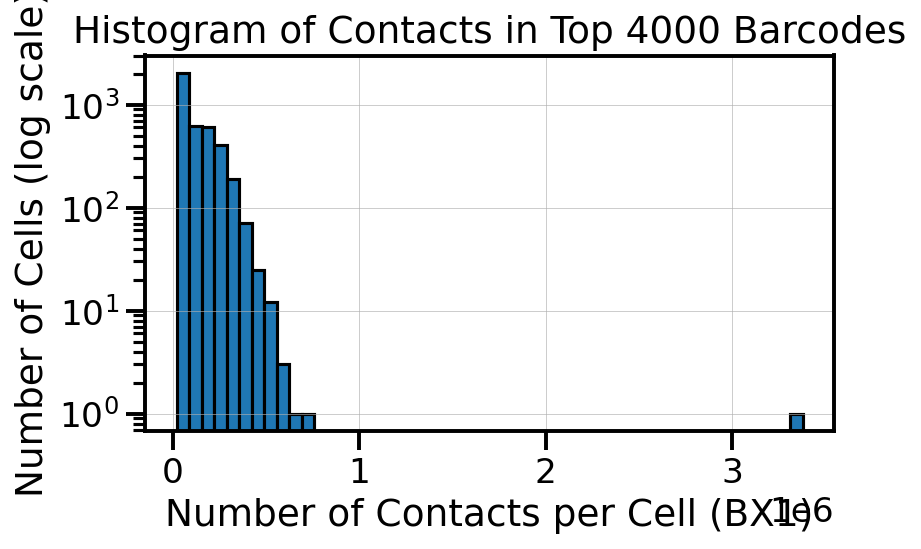

In [57]:
# Step 1. Count contacts per BX1
barcode_counts = (
    filtered_df
    .group_by("BX1")
    .agg(pl.count().alias("count"))
    .sort("count", descending=True)   # like pandas value_counts().sort
)

# Step 2. Take top 2000 and collect to eager DataFrame
top_counts = barcode_counts.head(4000).collect()

# Step 3. Convert to pandas for plotting
top_counts_pd = top_counts["count"].to_pandas()

# Step 4. Plot histogram
plt.figure(figsize=(6, 4), dpi=150)
plt.hist(top_counts_pd, bins=50, edgecolor="black")
plt.xlabel("Number of Contacts per Cell (BX1)")
plt.ylabel("Number of Cells (log scale)")
plt.title("Histogram of Contacts in Top 4000 Barcodes")
plt.yscale("log")
plt.tight_layout()
plt.grid(True, lw=0.3)
plt.show()

In [ ]:
#allow 1 mismatching

In [60]:
# Step 1. Count contacts per BX1
cnt_df = (
    df.group_by("BX1")
      .agg(pl.count().alias("count"))
      .sort("count", descending=True)
)

#Collect to eager DataFrame, then convert to pandas
cnt = cnt_df.collect().to_pandas().set_index("BX1")["count"]

# 2. Choose seed barcodes
seed_mask   = cnt > 100
seeds       = cnt[seed_mask].head(10000)      # pandas Series
seed_index  = set(seeds.index)               # fast membership
consolidated = seeds.to_dict()               # seed → final count

# 3. Build one-mismatch lookup table
bases = ["A", "C", "G", "T"]
variant_to_seed = {}

for bc in seed_index:
    variant_to_seed[bc] = bc                 # exact match
    for i, b in enumerate(bc):
        for alt in bases:
            if alt != b:
                v = bc[:i] + alt + bc[i+1:]
                # If collision: keep the seed with higher count
                if v not in variant_to_seed or seeds[bc] > seeds.get(variant_to_seed[v], 0):
                    variant_to_seed[v] = bc

# 4. Fold non-seed barcodes into seeds if ≤1 mismatch
for bc, n in cnt.items():
    if bc in seed_index:
        continue
    target = variant_to_seed.get(bc)
    if target:
        consolidated[target] += n

# 5. Final collapsed counts
final_cnt = pl.DataFrame({
    "BX1": list(consolidated.keys()),
    "count": list(consolidated.values())
}).sort("count", descending=True)

print(final_cnt.head())

shape: (5, 2)
┌──────────────────┬─────────┐
│ BX1              ┆ count   │
│ ---              ┆ ---     │
│ str              ┆ i64     │
╞══════════════════╪═════════╡
│ GGGGGGGGGGGGGGGG ┆ 3470201 │
│ TTCCCAGACCATGATC ┆ 738255  │
│ TAGTGCTGAACCGTGC ┆ 660252  │
│ TTCTAGTACGGGTAGT ┆ 623800  │
│ GTAGGTGGATCTGGGC ┆ 598939  │
└──────────────────┴─────────┘


In [61]:
n_above_10000 = final_cnt.filter(pl.col("count") > 20000).height
print(n_above_10000)

4308


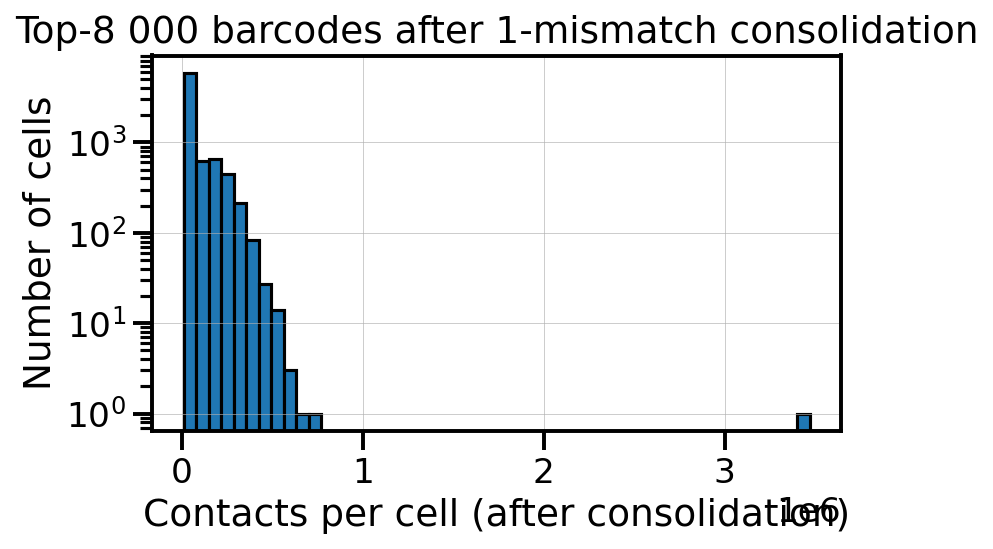

In [62]:
# Step 1. Take top-4000 barcodes
top2k = final_cnt.head(8000)

# Step 2. Extract counts as NumPy array (or pandas Series)
counts = top2k["count"].to_numpy()

# Step 3. Plot histogram
plt.figure(figsize=(6, 4), dpi=150)
plt.hist(counts, bins=50, edgecolor="black")
plt.xlabel("Contacts per cell (after consolidation)")
plt.ylabel("Number of cells")
plt.yscale("log")
plt.title("Top-8 000 barcodes after 1-mismatch consolidation")
plt.grid(True, lw=0.3)
plt.tight_layout()
plt.show()

# plot single cell heatmap and pairwise distance density plot

In [39]:
# Step 1: Get top 10 most covered barcodes
top10_barcodes = (
    df
    .group_by("BX1")
    .agg(pl.count().alias("count"))
    .sort("count", descending=True)
    .head(10)
    .collect()["BX1"]
    .to_list()
)

print(top10_barcodes)

/tmp/ipykernel_2747383/2644613772.py:5: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
  .agg(pl.count().alias("count"))


['GGGGGGGGGGGGGGGG', 'GTTCAGAACCCACAAT', 'GATAAGAACAACGTGG', 'CGTTATGGAGCCGCTA', 'CTATTCAACGATAGCG', 'ACTAACCGAAATCGAA', 'TTTGGGATGGAGTAAT', 'CGATAAAGATGCTTGA', 'CGGATGAGAGTGAGCA', 'CAGAAACCTGGACCTC']


In [40]:
# 2.  Build one matrix per barcode (H1)
BIN_SIZE = 10_000_000
mats = []

for bc in top10_barcodes:
    # Step 1. Filter for one barcode
    cell_pl = df.filter(pl.col("BX1") == bc)

    # Step 2. Filter out short-range cis contacts (<1 kb)
    cell_pl = cell_pl.filter(
        ~(
            (pl.col("chrom1") == pl.col("chrom2"))
            & ((pl.col("pos1") - pl.col("pos2")).abs() < 1000)
        )
    )

    # Step 3. Collect to eager Polars and convert to pandas
    cell_df = cell_pl.collect(streaming=True).to_pandas()

    # Step 4. Use your existing pandas functions
    bed_df = pairs_to_bedlike(cell_df)
    mat = get_pixels(bed_df, binsize=BIN_SIZE, cond=bc)
    mats.append(mat)

GGGGGGGGGGGGGGGG | direct interactions (gap<100): 144849
count trans/cis/diag/total : 109820 35029 22867 144849
generated symmetric matrix 323×323
GTTCAGAACCCACAAT | direct interactions (gap<100): 17423
count trans/cis/diag/total : 5038 12385 10611 17423
generated symmetric matrix 323×323
GATAAGAACAACGTGG | direct interactions (gap<100): 16477
count trans/cis/diag/total : 5065 11412 10061 16477
generated symmetric matrix 323×323
CGTTATGGAGCCGCTA | direct interactions (gap<100): 15043
count trans/cis/diag/total : 4536 10507 9251 15043
generated symmetric matrix 323×323
CTATTCAACGATAGCG | direct interactions (gap<100): 14735
count trans/cis/diag/total : 5637 9098 7432 14735
generated symmetric matrix 323×323
ACTAACCGAAATCGAA | direct interactions (gap<100): 12064
count trans/cis/diag/total : 3892 8172 7143 12064
generated symmetric matrix 323×323
TTTGGGATGGAGTAAT | direct interactions (gap<100): 15140
count trans/cis/diag/total : 4318 10822 9198 15140
generated symmetric matrix 323×323
C

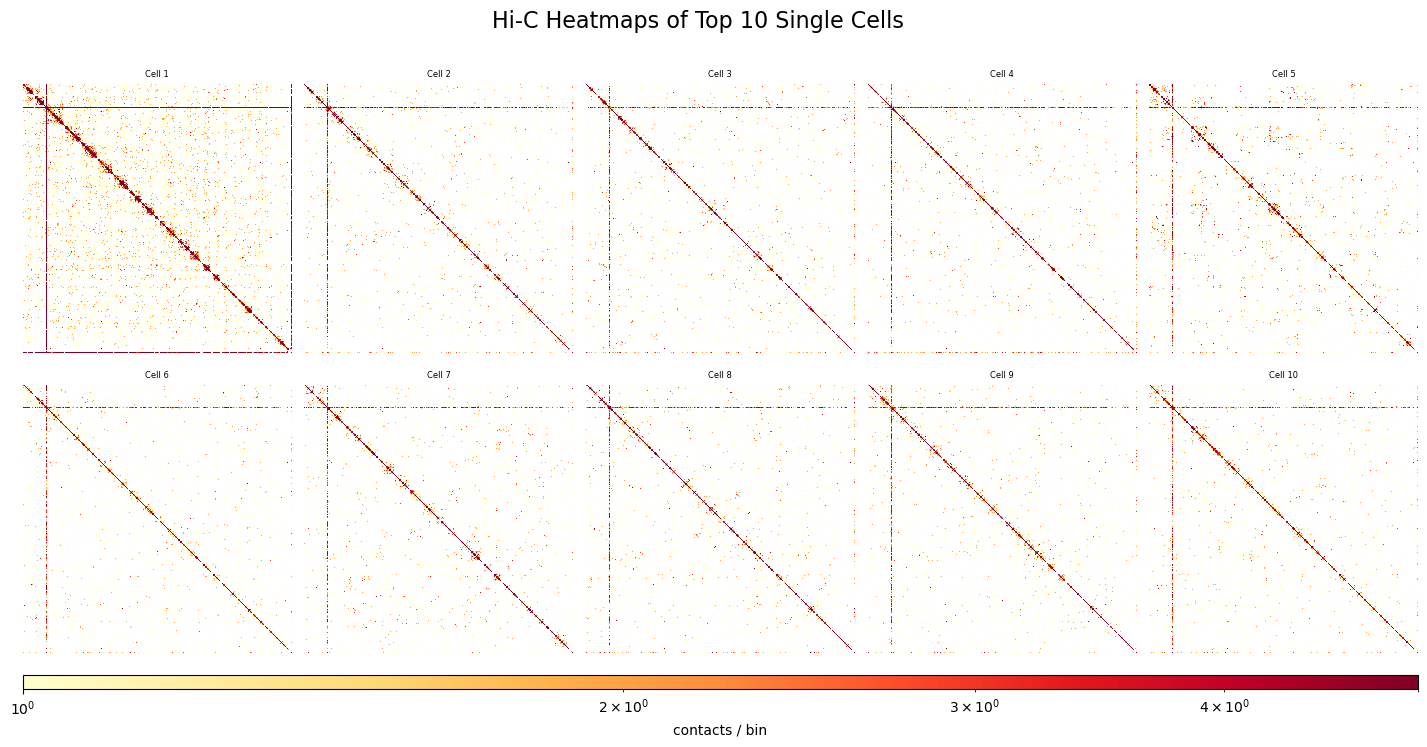

In [42]:
# 3.  Plot 10 heatmaps (2 × 5) with colour-bar underneath (mHep)
n_rows, n_cols = 2, 5
fig = plt.figure(figsize=(18, 8))
gs  = gridspec.GridSpec(
    n_rows + 1, n_cols,
    height_ratios=[1]*n_rows + [0.05],
    hspace=0.05, wspace=0.05
)

# --- Plot 10 heatmaps ---
for i, mat in enumerate(mats):
    ax = fig.add_subplot(gs[i])
    im = ax.imshow(
        mat,
        cmap="YlOrRd",
        norm=colors.LogNorm(vmin=1, vmax=5),
        interpolation="none",
        origin="upper"
    )
    ax.set_title(f"Cell {i+1}", fontsize=6)
    ax.axis("off")

# --- Shared colorbar ---
cbar_ax = fig.add_subplot(gs[-1, :])   # last row, span all columns
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('contacts / bin')

plt.suptitle("Hi-C Heatmaps of Top 10 Single Cells", fontsize=16, y=0.96)
plt.show()

# select the good cells use mitosis_band VS short_distance_band

In [69]:
# Step 1. Count contacts per BX1
#counts = df.group_by("BX1").agg(pl.count().alias("cnt"))
counts = df.group_by("BX1").agg(pl.count().alias("cnt"))

# Step 2. Join counts back to df
df_with_counts = df.join(counts, on="BX1")

# Step 3. Filter for BX1 with > 5000 contacts
filtered_df = df_with_counts.filter(pl.col("cnt") > 10000)

# Step 4. Count unique BX1s
n_bx1 = filtered_df.select(pl.col("BX1").n_unique()).collect().item()

print(f"Number of BX1 with >10000 contacts: {n_bx1}")

Number of BX1 with >10000 contacts: 7563


In [70]:
# Organize ShortVSMitotic dataframe
# --- Step 1: Filter and compute absolute distance
df = (
    filtered_df
    .filter(pl.col("chrom1") == pl.col("chrom2"))
    .filter(pl.col("chrom1").is_in(hg38_arms["chrom"].to_list()))
    .with_columns((pl.col("pos1") - pl.col("pos2")).abs().alias("Abs_Dist"))
)

# --- Step 2: Define masks (as expressions, not materialized Series)
mask_total   = pl.col("Abs_Dist") > 1500
mask_short   = pl.col("Abs_Dist").is_between(1500, 2_000_000)
mask_mitotic = pl.col("Abs_Dist").is_between(2_000_000, 12_000_000)

# --- Step 3: Count interactions per barcode for each category
total_counts = df.filter(mask_total).group_by("BX1").agg(pl.count().alias("total"))
short_counts = df.filter(mask_short).group_by("BX1").agg(pl.count().alias("short"))
mitotic_counts = df.filter(mask_mitotic).group_by("BX1").agg(pl.count().alias("mitotic"))

# --- Step 4: Align by joining on BX1
counts = (
    total_counts.join(short_counts, on="BX1", how="outer")
                .join(mitotic_counts, on="BX1", how="outer")
                .fill_null(0)  # replace missing with 0
)

# --- Step 5: Calculate ratios with small epsilon
counts = counts.with_columns([
    (pl.col("short") / (pl.col("total") + 1e-3)).alias("Short_ratio(1.5K-2Mb)"),
    (pl.col("mitotic") / (pl.col("total") + 1e-3)).alias("Mitotic_ratio(2Mb-12Mb)")
])

# --- Step 6: Compute total contacts regardless of distance
num_contacts = df.group_by("BX1").agg(pl.count().alias("Num_Contacts"))

# --- Step 7: Merge into final DataFrame
ShortVSMitotic_pl = (
    counts.join(num_contacts, on="BX1", how="outer")
          .fill_null(0)
          .select([
              pl.col("BX1").alias("barcodes"),
              "Short_ratio(1.5K-2Mb)",
              "Mitotic_ratio(2Mb-12Mb)",
              "Num_Contacts"
          ])
)

ShortVSMitotic_df = ShortVSMitotic_pl.collect().to_pandas()
ShortVSMitotic_df

,barcodes,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts
0,GCTGTTCTGTCGACAT,0.788203,0.099345,233252
1,TTTCTCGCTTAACGAA,0.684175,0.052629,12244
2,TAATTGCCTATGGCCC,0.641017,0.051281,20031
3,TCGTTCGTGCTGGGTC,0.446421,0.071427,19414
4,ACGCCACGATGTCACA,0.526307,0.070174,13303
...,...,...,...,...
7558,TAAGTGCACCATGCAT,0.574986,0.074998,15146
7559,CAATCGCCTGACACCC,0.768603,0.095133,185524
7560,TATGGGTACTCGTCCT,0.589728,0.051281,10600
7561,CTTTCCGGATGAGCAG,0.638888,0.113756,44997


In [71]:
#remove the "GGGGGGGGGGGGGGGG"
ShortVSMitotic_df = ShortVSMitotic_df[ShortVSMitotic_df['barcodes'] != 'GGGGGGGGGGGGGGGG']

In [76]:
ShortVSMitotic_df[ShortVSMitotic_df['Num_Contacts'] > 30000]

,barcodes,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts
0,GCTGTTCTGTCGACAT,0.788203,0.099345,233252
11,GCCAATATGAACGTTC,0.528564,0.042857,30692
13,CAAGAATGATAAGCAA,0.780070,0.087821,239542
20,TCCGGGAACCAGGTGA,0.565473,0.077380,41065
23,GGTACTCCTGCGCAAA,0.711228,0.069519,58268
...,...,...,...,...
7556,CGTTATGGACGATTAC,0.753816,0.093546,220299
7557,GGGATGTGAAAGTTCC,0.754244,0.093123,275704
7559,CAATCGCCTGACACCC,0.768603,0.095133,185524
7561,CTTTCCGGATGAGCAG,0.638888,0.113756,44997


In [77]:
#different-stage
#plot the mitosis VS interphase (mHep)
import plotly.express as px

# Filter
df = ShortVSMitotic_df[ShortVSMitotic_df['Num_Contacts'] > 20000]

# Plot without color grouping (all dots orange)
fig = px.scatter(df, x='Mitotic_ratio(2Mb-12Mb)', y='Short_ratio(1.5K-2Mb)')

fig.update_traces(
    marker=dict(
        size=5,
        opacity=0.8,
        color='orange'  # Set all markers to orange
    )
)

# Layout adjustments
fig.update_layout(
    title="Short VS mitotic contacts ratio per cell (>20K)",
    autosize=False,
    width=500,
    height=500,
    margin=dict(l=30, r=30, t=30, b=20),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    showlegend=False
)

# Add rectangles
fig.update_layout(
    shapes=[
        dict(type='rect', xref='x', yref='y', x0=0, y0=0, x1=0.4, y1=1, line=dict(color='black', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.02, y0=0.7, x1=0.15, y1=0.9, line=dict(color='blue', width=1)),
        dict(type='rect', xref='x', yref='y', x0=0.25, y0=0.45, x1=0.38, y1=0.65, line=dict(color='red', width=1))
#        dict(type='rect', xref='x', yref='y', x0=0.02, y0=0.6, x1=0.15, y1=0.8, line=dict(color='blue', width=1)),
#        dict(type='rect', xref='x', yref='y', x0=0.25, y0=0.4, x1=0.38, y1=0.6, line=dict(color='red', width=1))

    ]
)

# Save as PDF
fig.write_image("/home/xiangru.huo-umw/scHiC/scripts/plot/dropletHiCinDE_Short VS mitotic contacts ratio per cell (>20K).pdf", 
                width=450, height=400, scale=2, format='pdf')

# Show plot
fig.show()

In [74]:
#different-stages
#save the selected cells
#selected interphase or ProM cells dataframe
Interphase_cell_df = ShortVSMitotic_df[(ShortVSMitotic_df['Short_ratio(1.5K-2Mb)'] > 0.6)& (ShortVSMitotic_df['Short_ratio(1.5K-2Mb)'] < 0.8) & (ShortVSMitotic_df['Mitotic_ratio(2Mb-12Mb)'] < 0.15)]
ProM_cell_df = ShortVSMitotic_df[(ShortVSMitotic_df['Short_ratio(1.5K-2Mb)'] < 0.65) & (ShortVSMitotic_df['Mitotic_ratio(2Mb-12Mb)'] > 0.25)]
#selected cell with contacts > 30K 
Interphase_cell_30K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 30000]
ProM_cell_30K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 30000]
#selected cell with contacts > 20K 
Interphase_cell_20K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 20000]
ProM_cell_20K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 20000]
#selected cell with contacts > 10K 
Interphase_cell_10K = Interphase_cell_df[Interphase_cell_df['Num_Contacts'] > 10000]
ProM_cell_10K = ProM_cell_df[ProM_cell_df['Num_Contacts'] > 10000]

Interphase_cell_10K

,barcodes,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),Num_Contacts
0,GCTGTTCTGTCGACAT,0.788203,0.099345,233252
1,TTTCTCGCTTAACGAA,0.684175,0.052629,12244
2,TAATTGCCTATGGCCC,0.641017,0.051281,20031
6,AATTGCCGAACTCGAT,0.773770,0.086339,28036
13,CAAGAATGATAAGCAA,0.780070,0.087821,239542
...,...,...,...,...
7552,TAACGTTCTGGTTGAG,0.649111,0.122805,14030
7556,CGTTATGGACGATTAC,0.753816,0.093546,220299
7557,GGGATGTGAAAGTTCC,0.754244,0.093123,275704
7559,CAATCGCCTGACACCC,0.768603,0.095133,185524


In [75]:
#saving cell info into txt 
##
Interphase_cell_df.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_interphase_cell.txt", sep='\t', index=True)
ProM_cell_df.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_proM_cell.txt", sep='\t', index=True)
Interphase_cell_10K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_interphase_cell_10K.txt", sep='\t', index=True)
ProM_cell_10K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_proM_cell_10K.txt", sep='\t', index=True)
Interphase_cell_20K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_interphase_cell_20K.txt", sep='\t', index=True)
ProM_cell_20K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_proM_cell_20K.txt", sep='\t', index=True)
Interphase_cell_30K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_interphase_cell_30K.txt", sep='\t', index=True)
ProM_cell_30K.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_proM_cell_30K.txt", sep='\t', index=True)

# plot density of pairwise interaction distance

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



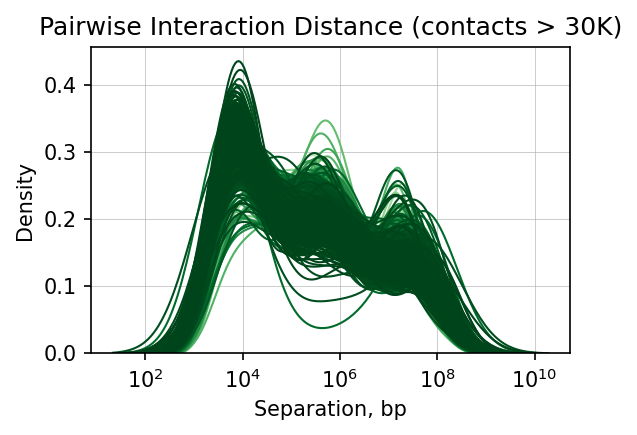

In [23]:
#mHep-stage: plot G1 
# --- Step 1: Get selected barcodes ---
selected_cells_df = Interphase_cell_30K  # or ProM_cell_30K
selected_barcodes = selected_cells_df["barcodes"].unique().tolist()  # <- fix here

# --- Step 2: Filter dropletHiC by selected barcodes ---
df_pl = filtered_df.filter(pl.col("BX1").is_in(selected_barcodes))

# --- Step 3: Keep only intra-chromosomal contacts and compute Abs_Dist ---
df_pl = (
    df_pl
    .filter(pl.col("chrom1") == pl.col("chrom2"))
    .with_columns((pl.col("pos1") - pl.col("pos2")).abs().alias("Abs_Dist"))
    .filter(pl.col("Abs_Dist") > 2000)  # remove <2kb artifacts
)

# --- Step 4: Merge contact counts ---
barcode_to_contacts = (
    selected_cells_df.set_index("barcodes")["Num_Contacts"].to_dict()
)

df_pl = df_pl.with_columns(
    pl.col("BX1").map_elements(barcode_to_contacts.get).alias("Contacts")
)

# --- Step 5: Convert to pandas for plotting ---
df_pd = df_pl.collect().to_pandas()

# --- Step 6: KDE plot ---
plt.figure(figsize=(4, 3), dpi=150)
sns.kdeplot(
    data=df_pd,
    x="Abs_Dist",
    hue="Contacts",
    palette="Greens_r",   # or samplecolor_sc
    lw=1,
    common_norm=False,
    log_scale=True,
    legend=False
)

plt.xlabel("Separation, bp")
plt.ylabel("Density")
plt.title("Pairwise Interaction Distance (contacts > 30K)")
plt.grid(lw=0.3)
plt.tight_layout()
plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot/DropletH1_Interphase_30K_Distance_Density.pdf",
    dpi=200
)
plt.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



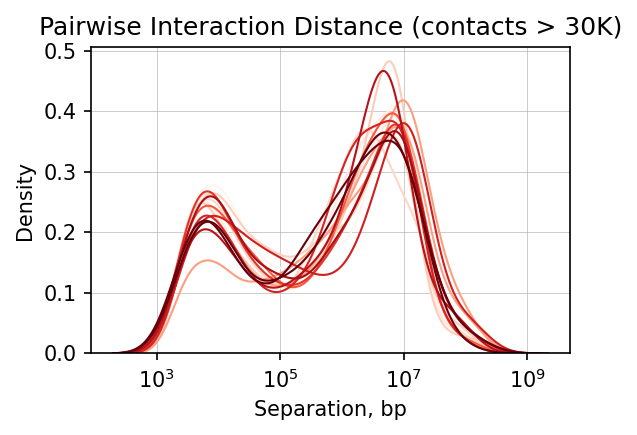

In [24]:
#mHep-stage: plot proM
# --- Step 1: Get selected barcodes ---
selected_cells_df = ProM_cell_30K  # or ProM_cell_30K
selected_barcodes = selected_cells_df["barcodes"].unique().tolist()  # <- fix here

# --- Step 2: Filter dropletHiC by selected barcodes ---
df_pl = filtered_df.filter(pl.col("BX1").is_in(selected_barcodes))

# --- Step 3: Keep only intra-chromosomal contacts and compute Abs_Dist ---
df_pl = (
    df_pl
    .filter(pl.col("chrom1") == pl.col("chrom2"))  # intra-chromosomal
    .with_columns((pl.col("pos1") - pl.col("pos2")).abs().alias("Abs_Dist"))
    .filter(pl.col("Abs_Dist") > 2000)             # remove artifacts
)

# --- Step 4: Merge contact counts ---
barcode_to_contacts = (
    selected_cells_df.set_index("barcodes")["Num_Contacts"].to_dict()
)

df_pl = df_pl.with_columns(
    pl.col("BX1").map_elements(barcode_to_contacts.get).alias("Contacts")
)

# --- Step 5: Convert to pandas for plotting ---
df_pd = df_pl.collect().to_pandas()

# --- Step 6: KDE plot ---
plt.figure(figsize=(4, 3), dpi=150)
sns.kdeplot(
    data=df_pd,
    x="Abs_Dist",
    hue="Contacts",
    palette="Reds_r",    # or samplecolor_sc
    lw=1,
    common_norm=False,
    log_scale=True,
    legend=False
)

plt.xlabel("Separation, bp")
plt.ylabel("Density")
plt.title("Pairwise Interaction Distance (contacts > 30K)")
plt.grid(lw=0.3)
plt.tight_layout()
plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot/DropletH1_Mitosis_30K_Distance_Density.pdf",
    dpi=200
)
plt.show()

# count cis/total ratio

In [5]:
#get compartment files (100kb) of 5 stages of bulk HiC (rep 2)
#path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/compartment_bulk"
path = '/pi/job.dekker-umw/home/johan.gibcus-umw/projects/UM1/compartments'
os.chdir(path)
os.getcwd()

#comp = pd.read_csv('ESC-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
#comp = pd.read_csv('DE-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
#comp = pd.read_csv('HB-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
comp = pd.read_csv('iHEP-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
#comp = pd.read_csv('mHEP-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)

print(len(comp.dropna()))

27153


In [6]:
#compartment A/B separated into two parts 
comp_A = {}
comp_B = {}

comp_A = comp[comp['E1']>0]
comp_B = comp[comp['E1']<0]
comp_A = comp_A.loc[:,['chrom','start','end']]
comp_A['comp'] = 'A'
comp_B = comp_B.loc[:,['chrom','start','end']]
comp_B['comp'] = 'B'

In [7]:
#identify unique_chrom_value
unique_chrom = comp['chrom'].unique()
#remove chrM from unique_chrom
unique_chrom_nuclei = unique_chrom[:-1]

In [8]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [9]:
#apply "split_df_by_chrom" function 
comp_split = split_df_by_chrom(comp)

In [10]:
#define a bin combine function (1M = 10, 2M = 20)
def create_continuous_ranges(df, Mg):
    original_list = df.index 
    # Split the indices into lists of length Mg
    index_lists = [original_list[i:i+Mg] for i in range(0, len(original_list), Mg)]

    df_Mg = pd.DataFrame(columns=["chrom", "start", "end", "E1"])
    
    # Loop through the index_lists
    for indices in index_lists:
        start_index = indices[0]
        end_index = indices[-1]       
        # Create a temporary DataFrame for the current continuous range
        df_continues_tmp = pd.DataFrame({
            "chrom": [df['chrom'][start_index]],
            "start": [df['start'][start_index]],
            "end": [df['end'][end_index]],
            "E1": [df['E1'][start_index:end_index].mean()]
        })        
        # Concatenate the temporary DataFrame to the main DataFrame
        df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
        df_Mg['start'] = df_Mg['start'].astype(int)
        df_Mg['end'] = df_Mg['end'].astype(int)
        df_Mg['E1'] = df_Mg['E1'].astype(float)
    
    # Add a Bin_ID column to the DataFrame
    df_Mg["Bin_ID"] = df_Mg["chrom"] + "_Bin" + df_Mg.index.astype(str)
    
    return df_Mg

In [11]:
#apply "create_continuous_ranges" function on comp_split
comp_chrom_bin = {}
for chrom in unique_chrom_nuclei:
    comp_chrom_bin[chrom] = create_continuous_ranges(comp_split[chrom], 10)

/tmp/ipykernel_2800280/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_2800280/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_2800280/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or 

In [12]:
#get comp bin all 
comp_bin = pd.concat(comp_chrom_bin.values(), ignore_index=True)

In [143]:
def generate_contacts_bin_id(df_pl, comp_bin):
    """
    Assigns bin IDs to each contact using comp_bin.
    df_pl: Polars LazyFrame or DataFrame with columns [chrom1,pos1,chrom2,pos2,BX1]
    comp_bin: pandas DataFrame with bin definitions (from bioframe.make_bins, etc.)
    Returns: pandas.DataFrame with bin IDs assigned
    """

    # --- Part A: process chrom1/pos1 ---
    df1_pd = (
        df_pl.select(["chrom1", "pos1"])
             .collect()
             .to_pandas()
             .rename(columns={"chrom1": "chrom", "pos1": "start"})
    )
    df1_pd["start"] = pd.to_numeric(df1_pd["start"], errors="coerce")
    df1_pd["end"] = df1_pd["start"] + 1

    df1_binID = bf.overlap(df1_pd, comp_bin, how="left", suffixes=("_1", "_2"))
    df1_binID = df1_binID.loc[:, ["chrom_1", "start_1", "Bin_ID_2"]]
    df1_binID.columns = ["chrom1", "pos1", "Bin_ID_1"]

    # --- Part B: process chrom2/pos2/BX1 ---
    df2_pd = (
        df_pl.select(["chrom2", "pos2", "BX1"])
             .collect()
             .to_pandas()
             .rename(columns={"chrom2": "chrom", "pos2": "start", "BX1": "barcodes"})
    )
    df2_pd["start"] = pd.to_numeric(df2_pd["start"], errors="coerce")
    df2_pd["end"] = df2_pd["start"] + 1

    df2_binID = bf.overlap(df2_pd, comp_bin, how="left", suffixes=("_1", "_2"))
    df2_binID = df2_binID.loc[:, ["chrom_1", "start_1", "Bin_ID_2", "barcodes_1"]]
    df2_binID.columns = ["chrom2", "pos2", "Bin_ID_2", "barcodes"]

    # --- Part C: concatenate results (pandas) ---
    df_binID = pd.concat([df1_binID, df2_binID], axis=1)

    return df_binID

In [144]:
#H1 stages
#file_path ="/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0403_ES/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#file_path ="/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0403_ES/droplethic_merged_dedup_sorted_UU_larger0.3kb.pairs"

# DE stages 
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/DE/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/DE/droplethic_merged_dedup_sorted_UU_larger0.3kb.pairs"

# HB stages 
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/HB/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/HB/droplethic_merged_dedup_sorted_UU_larger0.3kb.pairs"

# iHep stages 
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/iHep/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025_1114_DE_iHep_mHep/iHep/droplethic_merged_dedup_sorted_UU_larger0.3kb.pairs"

# mHep stages 
#file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0919_mHep/droplethic_merged_dedup_sorted_UU_larger0.4kb.pairs"
file_path = "/home/xiangru.huo-umw/scHiC/dropletHiC/2025-0919_mHep/droplethic_merged_dedup_sorted_UU_larger0.3kb.pairs"


# Scan (lazy, streaming)
df_larger1kb = pl.scan_csv(
    file_path,
    separator="\t",
    comment_char="#",
    has_header=False,
    quote_char='"',
    null_values=["null"]
)

# Assign column names
df_larger1kb = df_larger1kb.rename({
    "column_1": "readID", "column_2": "chrom1", "column_3": "pos1",
    "column_4": "chrom2", "column_5": "pos2", "column_6": "strand1",
    "column_7": "strand2", "column_8": "pair_type", "column_9": "mapq1",
    "column_10": "mapq2", "column_11": "BX1", "column_12": "BX2"
})

In [145]:
# reduce the contact table by only keeping contacts > 20000 cells
counts = df_larger1kb.group_by("BX1").agg(pl.count().alias("cnt"))

# Step 2. Join counts back to df
df_with_counts = df_larger1kb.join(counts, on="BX1")

In [146]:
# Call the function "generate_contacts_Bin_id" and store the result
# Read Interphase file

# --- Step 1: Load your selected cells (pandas) ---
#H1
#Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_interphase_cell_20K.txt",sep="\t",index_col=0)
#DE
#Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_interphase_cell_20K.txt",sep="\t",index_col=0)
#HB
#Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_HB_interphase_cell_20K.txt",sep="\t",index_col=0)
#iHep 
#Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_iHep_interphase_cell_20K.txt",sep="\t",index_col=0)
#mHep
Interphase_cell_20K = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_interphase_cell_20K.txt",sep="\t",index_col=0)


selected_cells_df = Interphase_cell_20K
selected_barcodes = selected_cells_df["barcodes"].unique().tolist()
selected_barcodes = [str(b).strip('" ') for b in selected_barcodes]  # normalize

# --- Step 2: Clean up Polars contact table ---
df_with_counts = df_with_counts.with_columns(
    pl.col("BX1").str.strip_chars('" ')
).filter(pl.col("BX1") != "BX1")  # drop bogus header row

# --- Step 3: Quick overlap check ---
overlap_count = (
    df_with_counts
    .select(pl.col("BX1").is_in(selected_barcodes).sum().alias("overlap"))
    .collect()
    .item()
)

print(f"Overlap barcodes: {overlap_count} / {len(selected_barcodes)}")

# --- Step 4: Filter by selected barcodes ---
df_sel = df_with_counts.filter(pl.col("BX1").is_in(selected_barcodes))

# --- Step : Call the function ---
stage_contacts_Bin_ID = generate_contacts_bin_id(df_sel, comp_bin)

Overlap barcodes: 5309146 / 663


In [147]:
stage_contacts_Bin_ID

,chrom1,pos1,Bin_ID_1,chrom2,pos2,Bin_ID_2,barcodes
0,chr1,630607,chr1_Bin0,chrM,5477,None,AAACGAAACCTCGATA
1,chr1,634038,chr1_Bin0,chrM,14468,None,AAACGAAACCTCGATA
2,chr1,634079,chr1_Bin0,chrM,10761,None,AAACGAAACCTCGATA
3,chr1,634111,chr1_Bin0,chrM,16324,None,AAACGAAACCTCGATA
4,chr1,3895926,chr1_Bin3,chrM,8237,None,AAACGAAACCTCGATA
...,...,...,...,...,...,...,...
5309141,chrX,98366611,chrX_Bin98,chr15,61001637,chr15_Bin61,TTTGCGGCTCCACTTC
5309142,chrX,103312485,chrX_Bin103,chrM,12016,None,TTTGCGGCTCCACTTC
5309143,chrX,126472620,chrX_Bin126,chrM,754,None,TTTGCGGCTCCACTTC
5309144,chrX,129291785,chrX_Bin129,chrX,129292388,chrX_Bin129,TTTGCGGCTCCACTTC


In [148]:
#define the function to get the cis_ratio per cell + count of inter-chromsomes 
def calculate_cis_ratio(df):
    # --- From pos1 (Bin_ID_1 vs chrom2) ---
    vc1 = df.groupby("Bin_ID_1")["chrom2"].value_counts()
    vc1 = vc1.reset_index(name="count")

    cis_count1 = vc1.groupby("Bin_ID_1")["count"].max().reset_index(name="cis_count1")
    total_count1 = vc1.groupby("Bin_ID_1")["count"].sum().reset_index(name="total_count1")

    cis_ratio = pd.merge(cis_count1, total_count1, on="Bin_ID_1", how="outer")
    cis_ratio["trans_count1"] = cis_ratio["total_count1"] - cis_ratio["cis_count1"]

    # --- From pos2 (Bin_ID_2 vs chrom1) ---
    vc2 = df.groupby("Bin_ID_2")["chrom1"].value_counts()
    vc2 = vc2.reset_index(name="count")

    cis_count2 = vc2.groupby("Bin_ID_2")["count"].max().reset_index(name="cis_count2")
    total_count2 = vc2.groupby("Bin_ID_2")["count"].sum().reset_index(name="total_count2")

    cis_ratio2 = pd.merge(cis_count2, total_count2, on="Bin_ID_2", how="outer")
    cis_ratio2.columns = ["Bin_ID_1", "cis_count2", "total_count2"]
    cis_ratio2["trans_count2"] = cis_ratio2["total_count2"] - cis_ratio2["cis_count2"]

    # --- Unique chrom1 counts per Bin_ID_2 (renamed to Bin_ID_1 for merge) ---
    unique_chrom1 = df.groupby("Bin_ID_2")["chrom1"].nunique().reset_index()
    unique_chrom1.columns = ["Bin_ID_1", "Chromosome_counts"]

    # --- Combine ---
    cis_ratio_all = pd.merge(cis_ratio, cis_ratio2, on="Bin_ID_1", how="outer")
    cis_ratio_all = pd.merge(cis_ratio_all, unique_chrom1, on="Bin_ID_1", how="left")

    # --- Final columns ---
    cis_ratio_all["cis_count_final"] = cis_ratio_all[["cis_count1", "cis_count2"]].max(axis=1)
    cis_ratio_all["trans_count_final"] = cis_ratio_all["trans_count1"].fillna(0) + cis_ratio_all["trans_count2"].fillna(0)
    cis_ratio_all["total_count_final"] = cis_ratio_all["cis_count_final"].fillna(0) + cis_ratio_all["trans_count_final"].fillna(0)
    cis_ratio_all["cis_ratio_final"] = cis_ratio_all["cis_count_final"] / cis_ratio_all["total_count_final"].replace(0, pd.NA)

    return cis_ratio_all

In [149]:
# Call the function "calculate_cis_ratio" and store the result
stage_cis_ratio_Bin_ID = {
    bc: calculate_cis_ratio(group.copy())
    for bc, group in stage_contacts_Bin_ID.groupby('barcodes')}

In [150]:
#get sum of cis_total ratio Bin_ID per cell
df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})

# Loop through each barcode/cell in stage_cis_ratio_Bin_ID
for bc in selected_barcodes:
    df = stage_cis_ratio_Bin_ID[bc]
    # Extract Bin_ID and cis_ratio
    df_tmp = df[['Bin_ID_1', 'cis_ratio_final']].copy()
    df_tmp.columns = ['Bin_ID_1', bc]  # Rename cis_ratio_final to barcode name
    # Merge with the running sum table
    df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
# Sort and set index
df_sum = df_sum.sort_values(by='Bin_ID_1').set_index('Bin_ID_1')
# Transpose to get barcodes as rows
cis_ratio_Bin_ID_sum = df_sum.T

In [151]:
#get sum of total cis_count_final of Bin_ID per cell
df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})

# Loop through each barcode/cell in stage_cis_ratio_Bin_ID
for bc in selected_barcodes:
    df = stage_cis_ratio_Bin_ID[bc]
    # Extract Bin_ID and cis_ratio
    df_tmp = df[['Bin_ID_1', 'cis_count_final']].copy()
    df_tmp.columns = ['Bin_ID_1', bc]  # Rename cis_ratio_final to barcode name
    # Merge with the running sum table
    df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
# Sort and set index
df_sum = df_sum.sort_values(by='Bin_ID_1').set_index('Bin_ID_1')
# Transpose to get barcodes as rows
cis_Bin_ID_sum = df_sum.T

In [152]:
#get sum of total cis_count_final of Bin_ID per cell
df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})

# Loop through each barcode/cell in stage_cis_ratio_Bin_ID
for bc in selected_barcodes:
    df = stage_cis_ratio_Bin_ID[bc]
    # Extract Bin_ID and cis_ratio
    df_tmp = df[['Bin_ID_1', 'total_count_final']].copy()
    df_tmp.columns = ['Bin_ID_1', bc]  # Rename cis_ratio_final to barcode name
    # Merge with the running sum table
    df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
# Sort and set index
df_sum = df_sum.sort_values(by='Bin_ID_1').set_index('Bin_ID_1')
# Transpose to get barcodes as rows
reads_Bin_ID_sum = df_sum.T

In [57]:
#H1-stage:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
# Save concatenated tables (keep index in the file)
#original one
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M.txt', sep='\t', index=True)
#filter
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M_filter<0.5kb.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M_filter<0.5kb.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M_filter<0.5kb.txt', sep='\t', index=True)

#filter
cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M_filter<0.3kb.txt', sep='\t', index=True)
reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M_filter<0.3kb.txt', sep='\t', index=True)
cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M_filter<0.3kb.txt', sep='\t', index=True)

In [96]:
#DE-stage:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
# Save concatenated tables (keep index in the file)
#filter
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_DE_>1M_filter<0.4kb.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_DE_>1M_filter<0.4kb.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_DE_>1M_filter<0.4kb.txt', sep='\t', index=True)

#filter
cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_DE_>1M_filter<0.3kb.txt', sep='\t', index=True)
reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_DE_>1M_filter<0.3kb.txt', sep='\t', index=True)
cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_DE_>1M_filter<0.3kb.txt', sep='\t', index=True)

In [23]:
#HB-stage:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
# Save concatenated tables (keep index in the file)
#filter
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_HB_>1M_filter<0.4kb.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_HB_>1M_filter<0.4kb.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_HB_>1M_filter<0.4kb.txt', sep='\t', index=True)

#filter
cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_HB_>1M_filter<0.3kb.txt', sep='\t', index=True)
reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_HB_>1M_filter<0.3kb.txt', sep='\t', index=True)
cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_HB_>1M_filter<0.3kb.txt', sep='\t', index=True)

In [153]:
#iHep-stage:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
# Save concatenated tables (keep index in the file)
#filter
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_iHep_>1M_filter<0.4kb.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_iHep_>1M_filter<0.4kb.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_iHep_>1M_filter<0.4kb.txt', sep='\t', index=True)

#filter
cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_iHep_>1M_filter<0.3kb.txt', sep='\t', index=True)
reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_iHep_>1M_filter<0.3kb.txt', sep='\t', index=True)
cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_iHep_>1M_filter<0.3kb.txt', sep='\t', index=True)

In [39]:
#mHep-stage:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
# Save concatenated tables (keep index in the file)
#original one
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M.txt', sep='\t', index=True)
#filter
#cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M_filter<0.4kb.txt', sep='\t', index=True)
#reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M_filter<0.4kb.txt', sep='\t', index=True)
#cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M_filter<0.4kb.txt', sep='\t', index=True)

#filter
cis_ratio_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M_filter<0.3kb.txt', sep='\t', index=True)
reads_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M_filter<0.3kb.txt', sep='\t', index=True)
cis_Bin_ID_sum.to_csv('/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M_filter<0.3kb.txt', sep='\t', index=True)

# get the folding variability score (following will not take to much memory)

In [13]:
#H1-stage:
#read files (unfiltered)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M.txt', sep='\t',index_col=0)

#read files (filtered 1kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M_filter<1kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M_filter<1kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M_filter<1kb.txt', sep='\t',index_col=0)

#read files (filtered 0.5kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M_filter<0.5kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M_filter<0.5kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M_filter<0.5kb.txt', sep='\t',index_col=0)

#read files (filtered 0.4kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M_filter<0.4kb.txt', sep='\t',index_col=0)

#read files (filtered 0.3kb out)
cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_H1_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_H1_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_H1_>1M_filter<0.3kb.txt', sep='\t',index_col=0)


#organize comp_bin_cisratio normalized with EGV together
df = comp_bin.copy()
df.set_index('Bin_ID', inplace=True)
df['cisratio_mean'] = cis_ratio_Bin_ID_sum.mean()
df['cisratio_S.D.'] = cis_ratio_Bin_ID_sum.std()
df['cisratio_cv'] = df['cisratio_S.D.'] / df['cisratio_mean']
df['total_counts_Mean'] = reads_Bin_ID_sum.mean(axis=0)
df['total_counts_sum'] = reads_Bin_ID_sum.sum(axis=0)

# Save to file
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio.txt'
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<1kb.txt'
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.5kb.txt'
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.4kb.txt'
droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.3kb.txt'


df.to_csv(droplet_comp_binfile_path, sep='\t', index=True)

In [14]:
droplet_comp_bin_cisratio_H1 = df
droplet_comp_bin_cisratio_H1

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,cisratio_IQR,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.592578,0.217024,0.366237,0.269841,9.832692,5113.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.596129,0.281632,0.472434,0.625000,5.525386,2503.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.635130,0.278183,0.437993,0.600000,3.857527,1435.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.622184,0.277077,0.445330,0.600000,4.854214,2131.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.646790,0.269553,0.416755,0.545455,6.165563,2793.0
...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [47]:
#mHep-stage:
#read files
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M.txt', sep='\t',index_col=0)

#read files (filtered 1kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M_filter<1kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M_filter<1kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M_filter<1kb.txt', sep='\t',index_col=0)

#read files (filtered 0.5kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M_filter<0.5kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M_filter<0.5kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M_filter<0.5kb.txt', sep='\t',index_col=0)

#read files (filtered 0.4kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M_filter<0.4kb.txt', sep='\t',index_col=0)

#read files (filtered 0.3kb out)
cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_mHep_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_mHep_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_mHep_>1M_filter<0.3kb.txt', sep='\t',index_col=0)

In [48]:
#mHep-stage:
#organize comp_bin_cisratio normalized with EGV together
df = comp_bin.copy()
df.set_index('Bin_ID', inplace=True)
df['cisratio_mean'] = cis_ratio_Bin_ID_sum.mean()
df['cisratio_S.D.'] = cis_ratio_Bin_ID_sum.std()
df['cisratio_cv'] = df['cisratio_S.D.'] / df['cisratio_mean']
df['total_counts_Mean'] = reads_Bin_ID_sum.mean(axis=0)
df['total_counts_sum'] = reads_Bin_ID_sum.sum(axis=0)

# Save to file
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio.txt'
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<1kb.txt'
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.5kb.txt'
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.4kb.txt'
droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.3kb.txt'

df.to_csv(droplet_comp_binfile_path, sep='\t', index=True)

In [49]:
droplet_comp_bin_cisratio_mHep = df
droplet_comp_bin_cisratio_mHep

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,cisratio_IQR,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.759990,0.249849,0.328753,0.500000,3.017391,694.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.802381,0.256651,0.319862,0.428571,2.581081,191.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.864524,0.218193,0.252385,0.312500,1.828571,128.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.847431,0.235267,0.277624,0.333333,2.065789,157.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.844882,0.230487,0.272804,0.400000,2.104167,202.0
...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [55]:
#HB stages
#read files (filtered 0.4kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_HB_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_HB_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_HB_>1M_filter<0.4kb.txt', sep='\t',index_col=0)

#read files (filtered 0.3kb out)
cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_HB_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_HB_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_HB_>1M_filter<0.3kb.txt', sep='\t',index_col=0)

#HB-stage:
#organize comp_bin_cisratio normalized with EGV together
df = comp_bin.copy()
df.set_index('Bin_ID', inplace=True)
df['cisratio_mean'] = cis_ratio_Bin_ID_sum.mean()
df['cisratio_S.D.'] = cis_ratio_Bin_ID_sum.std()
df['cisratio_cv'] = df['cisratio_S.D.'] / df['cisratio_mean']
df['total_counts_Mean'] = reads_Bin_ID_sum.mean(axis=0)
df['total_counts_sum'] = reads_Bin_ID_sum.sum(axis=0)

# Save to file
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_HB_comp_bin_cisratio_filter<0.4kb.txt'
droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_HB_comp_bin_cisratio_filter<0.3kb.txt'

df.to_csv(droplet_comp_binfile_path, sep='\t', index=True)

In [56]:
droplet_comp_bin_cisratio_HB = df
droplet_comp_bin_cisratio_HB

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,cisratio_IQR,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.596823,0.245030,0.410556,0.340278,5.710526,1302.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.711888,0.261434,0.367240,0.500000,4.140187,443.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.777696,0.261702,0.336510,0.500000,2.914634,239.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.735406,0.269579,0.366572,0.500000,3.647619,383.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.768597,0.264466,0.344089,0.500000,3.705882,441.0
...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [51]:
#iHep stages
#read files (filtered 0.4kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_iHep_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_iHep_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_iHep_>1M_filter<0.4kb.txt', sep='\t',index_col=0)

#read files (filtered 0.3kb out)
cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_iHep_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_iHep_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_iHep_>1M_filter<0.3kb.txt', sep='\t',index_col=0)


#iHep-stage:
#organize comp_bin_cisratio normalized with EGV together
df = comp_bin.copy()
df.set_index('Bin_ID', inplace=True)
df['cisratio_mean'] = cis_ratio_Bin_ID_sum.mean()
df['cisratio_S.D.'] = cis_ratio_Bin_ID_sum.std()
df['cisratio_cv'] = df['cisratio_S.D.'] / df['cisratio_mean']
df['total_counts_Mean'] = reads_Bin_ID_sum.mean(axis=0)
df['total_counts_sum'] = reads_Bin_ID_sum.sum(axis=0)

# Save to file
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_iHep_comp_bin_cisratio_filter<0.4kb.txt'
droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_iHep_comp_bin_cisratio_filter<0.3kb.txt'

df.to_csv(droplet_comp_binfile_path, sep='\t', index=True)

In [52]:
droplet_comp_bin_cisratio_iHep = df
droplet_comp_bin_cisratio_iHep

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,cisratio_IQR,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.568976,0.260007,0.456973,0.416667,7.989691,1550.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.648806,0.248689,0.383302,0.529412,9.585938,1227.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.724867,0.250882,0.346107,0.500000,5.235772,644.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.726688,0.250296,0.344434,0.500000,6.566176,893.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.686618,0.251641,0.366494,0.500000,6.726619,935.0
...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [53]:
#DE stages
#read files (filtered 0.4kb out)
#cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_DE_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_DE_>1M_filter<0.4kb.txt', sep='\t',index_col=0)
#cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_DE_>1M_filter<0.4kb.txt', sep='\t',index_col=0)

#read files (filtered 0.3kb out)
cis_ratio_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_cis_ratio_perBin_DE_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
reads_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_reads_perBin_DE_>1M_filter<0.3kb.txt', sep='\t',index_col=0)
cis_Bin_ID_sum = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_total_cis_perBin_DE_>1M_filter<0.3kb.txt', sep='\t',index_col=0)


#iHep-stage:
#organize comp_bin_cisratio normalized with EGV together
df = comp_bin.copy()
df.set_index('Bin_ID', inplace=True)
df['cisratio_mean'] = cis_ratio_Bin_ID_sum.mean()
df['cisratio_S.D.'] = cis_ratio_Bin_ID_sum.std()
df['cisratio_cv'] = df['cisratio_S.D.'] / df['cisratio_mean']
df['total_counts_Mean'] = reads_Bin_ID_sum.mean(axis=0)
df['total_counts_sum'] = reads_Bin_ID_sum.sum(axis=0)

# Save to file
#droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_comp_bin_cisratio_filter<0.4kb.txt'
droplet_comp_binfile_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_comp_bin_cisratio_filter<0.3kb.txt'

df.to_csv(droplet_comp_binfile_path, sep='\t', index=True)

In [54]:
droplet_comp_bin_cisratio_DE = df
droplet_comp_bin_cisratio_DE

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,cisratio_IQR,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.746757,0.284121,0.380473,0.500000,2.440476,410.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.652520,0.261510,0.400769,0.500000,4.627119,819.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.711235,0.259626,0.365036,0.500000,2.802721,412.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.642007,0.264363,0.411776,0.571429,3.833333,644.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.663004,0.263480,0.397403,0.500000,4.047904,676.0
...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0


# comparison between droplet HiC with the plate-base Hi-C

In [3]:
#mHep-stage: load the cis/total from plate-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_mHep_1M_noH1batch3.txt'
contact_dist = 300
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_mHep_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
plated_comp_bin_cisratio_mHep = df

#load the cis/total from droplet-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<1kb.txt'
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.5kb.txt'
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.4kb.txt'
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.3kb.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
droplet_comp_bin_cisratio_mHep = df
droplet_comp_bin_cisratio_mHep

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.713516,0.257925,0.361484,3.149656,5493.0
chr1_Bin1,chr1,1000000,2000000,1.553887,0.814882,0.237897,0.291940,2.468170,1861.0
chr1_Bin2,chr1,2000000,3000000,0.671571,0.876735,0.210932,0.240588,1.869718,1062.0
chr1_Bin3,chr1,3000000,4000000,0.513393,0.842051,0.223106,0.264956,2.254768,1655.0
chr1_Bin4,chr1,4000000,5000000,-0.206001,0.848997,0.217691,0.256410,2.431843,2230.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0


In [4]:
plated_comp_bin_cisratio_mHep

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum,trans_counts_Mean,chromnum_counts_Mean
Bin_ID,,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.498901,0.165426,0.331580,24.675676,913.0,11.918919,1.000000
chr1_Bin1,chr1,1000000,2000000,1.553887,0.802704,0.156798,0.195337,22.425532,1054.0,4.425532,1.000000
chr1_Bin2,chr1,2000000,3000000,0.671571,0.852200,0.148022,0.173694,26.446809,1243.0,3.893617,1.000000
chr1_Bin3,chr1,3000000,4000000,0.513393,0.885208,0.102938,0.116286,23.260870,1070.0,3.260870,1.000000
chr1_Bin4,chr1,4000000,5000000,-0.206001,0.864716,0.116091,0.134253,27.957447,1314.0,4.234043,1.000000
...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN


In [5]:
#HB-stage: load the cis/total from plate-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_HB_1M_noH1batch3.txt'
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_HB_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
plated_comp_bin_cisratio_HB = df

#load the cis/total from droplet-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_HB_comp_bin_cisratio_filter<0.4kb.txt'
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_HB_comp_bin_cisratio_filter<0.3kb.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
droplet_comp_bin_cisratio_HB = df

droplet_comp_bin_cisratio_HB

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.618837,0.252415,0.407887,5.477674,5275.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.789082,0.246805,0.312775,4.676768,2315.0
chr1_Bin2,chr1,2000000,3000000,0.775575,0.812113,0.240449,0.296079,3.527919,1390.0
chr1_Bin3,chr1,3000000,4000000,0.513051,0.776927,0.242569,0.312216,4.304260,2122.0
chr1_Bin4,chr1,4000000,5000000,0.172720,0.775819,0.243370,0.313694,4.766859,2474.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0


In [6]:
#iHep-stage: load the cis/total from plate-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_iHep_1M_noH1batch3.txt'
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_iHep_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
plated_comp_bin_cisratio_iHep = df

#load the cis/total from droplet-based HiC
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_iHep_comp_bin_cisratio_filter<0.4kb.txt'
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_iHep_comp_bin_cisratio_filter<0.3kb.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
droplet_comp_bin_cisratio_iHep = df

droplet_comp_bin_cisratio_iHep

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.592775,0.255023,0.430218,8.585774,2052.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.693620,0.246918,0.355985,10.943038,1729.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.745384,0.237807,0.319039,5.955128,929.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.748508,0.233849,0.312421,7.551724,1314.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.736814,0.240280,0.326106,7.960452,1409.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0


In [7]:
#DE-stage: load the cis/total from plate-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_DE_1M_noH1batch3.txt'
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_DE_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
plated_comp_bin_cisratio_DE = df

#load the cis/total from droplet-based HiC
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_comp_bin_cisratio_filter<0.4kb.txt'
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_comp_bin_cisratio_filter<0.3kb.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
droplet_comp_bin_cisratio_DE = df

droplet_comp_bin_cisratio_DE

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.694430,0.273141,0.393331,11.221172,5936.0
chr1_Bin1,chr1,1000000,2000000,NaN,0.670673,0.244153,0.364042,7.347107,3556.0
chr1_Bin2,chr1,2000000,3000000,0.661504,0.732201,0.250373,0.341946,5.024631,2040.0
chr1_Bin3,chr1,3000000,4000000,0.529714,0.685854,0.246135,0.358874,6.500000,3003.0
chr1_Bin4,chr1,4000000,5000000,0.175539,0.701132,0.244612,0.348881,9.355180,4425.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0


In [77]:
#ES stage load the cis/total from plate-based HiC
#note: in Fig1, we used droplet Hi-C dataset filter < 0.3kb
#note: in Fig3, we used droplet Hi-C dataset filter < 0.4kb (consistent setting compare with other stages)

#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_ES_1M_noH1batch3.txt'
contact_dist = 300
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_ES_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
plated_comp_bin_cisratio_H1 = df

#load the cis/total from droplet-based HiC
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<1kb.txt'
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.5kb.txt'
#file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.4kb.txt'
file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.3kb.txt'

df = pd.read_csv(file_path, sep='\t',index_col=0)
droplet_comp_bin_cisratio_H1 = df
droplet_comp_bin_cisratio_H1

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.579389,0.208921,0.360589,11.221172,5936.0
chr1_Bin1,chr1,1000000,2000000,0.827367,0.662800,0.244899,0.369491,7.347107,3556.0
chr1_Bin2,chr1,2000000,3000000,0.503929,0.688600,0.243636,0.353813,5.024631,2040.0
chr1_Bin3,chr1,3000000,4000000,0.436396,0.669554,0.245251,0.366291,6.500000,3003.0
chr1_Bin4,chr1,4000000,5000000,0.291384,0.715502,0.225935,0.315772,9.355180,4425.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,0.0


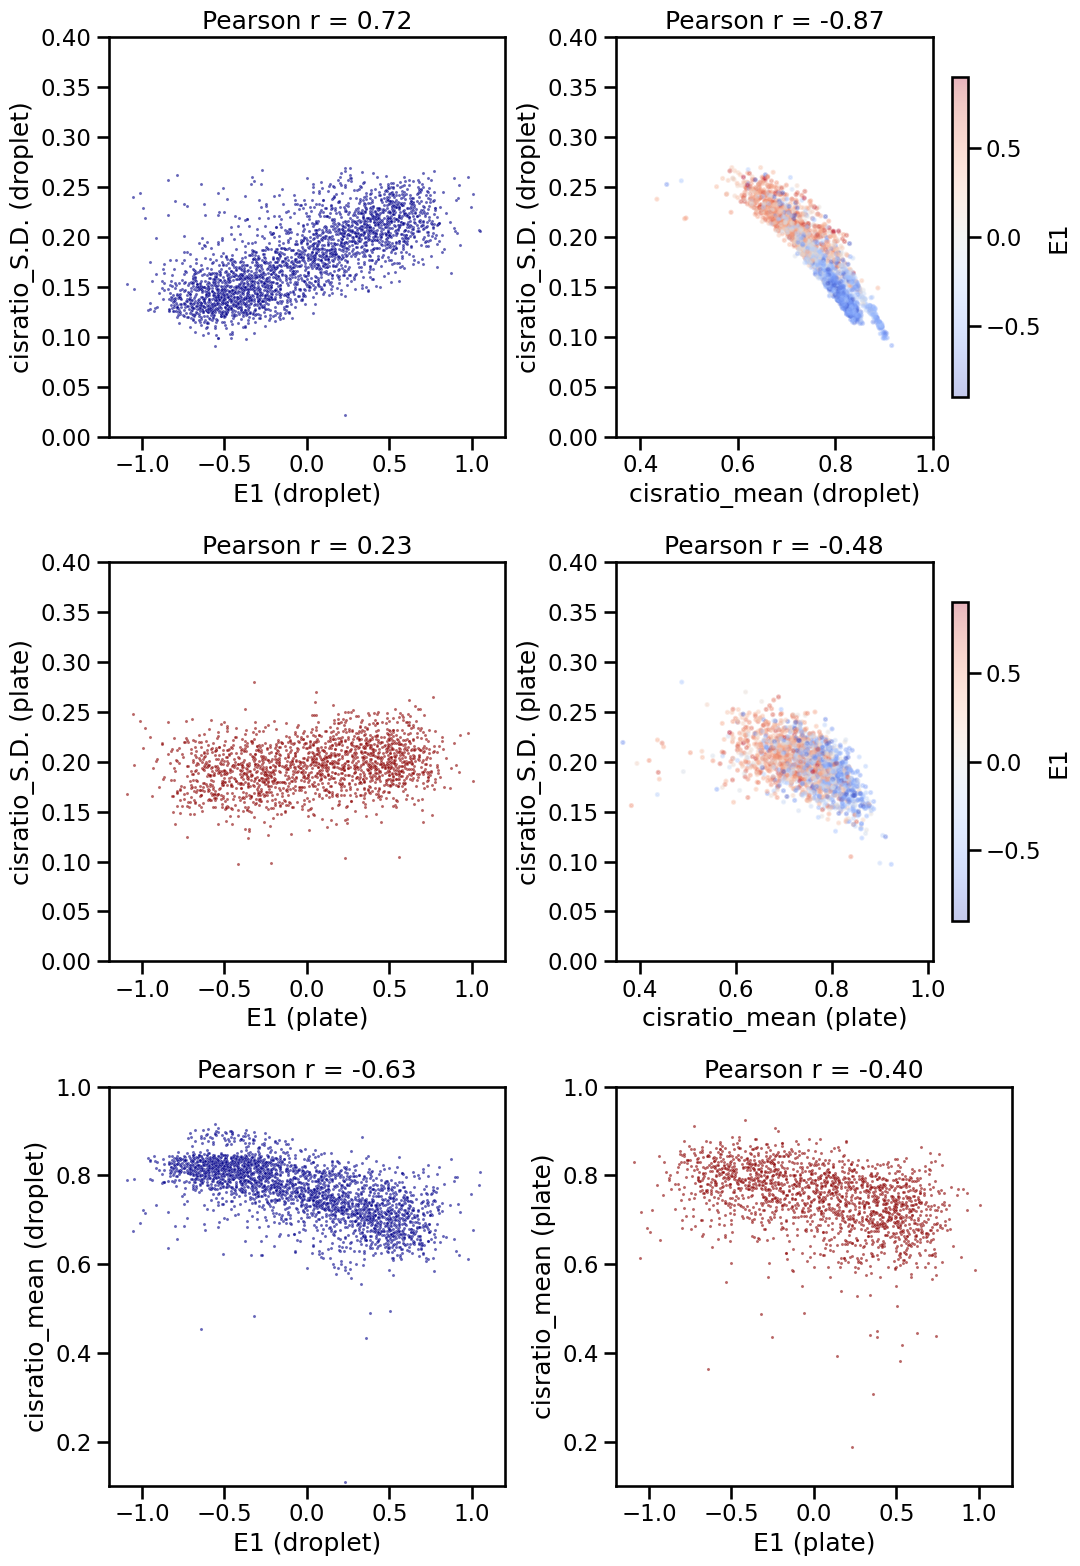

In [ ]:
# Step 1: Reset index to expose Bin_ID
#droplet_df = droplet_comp_bin_cisratio_mHep.reset_index()
#plate_df = plated_comp_bin_cisratio_mHep.reset_index()
droplet_df = droplet_comp_bin_cisratio_H1.reset_index()
plate_df = plated_comp_bin_cisratio_H1.reset_index()


#only use chr2
#droplet_df = droplet_df[droplet_df["chrom"] == "chr2"]
#plate_df = plate_df[plate_df["chrom"] == "chr2"]


# Step 2: Use all bins (filter the bin total interactions across whole cells < 1000)
droplet_all = droplet_df.copy()
plate_all = plate_df.copy()


droplet_all = droplet_all[droplet_all["total_counts_sum"] >= 2000] #iHep has fewer cells in droplet, so select < 500
plate_all   = plate_all[plate_all["total_counts_sum"] >= 1000]

# Step 3: Setup figure
fig, axes = plt.subplots(3, 2, figsize=(11, 16), dpi=100)
axes = axes.flatten()

# === Plot 1: Droplet — E1 vs cisratio_cv ===
x = droplet_all['E1']
y = droplet_all['cisratio_S.D.']
mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
r1, _ = pearsonr(x[mask], y[mask])

sns.scatterplot(x=x, y=y, ax=axes[0], s=5, alpha=0.6, color='darkblue')
axes[0].set_xlabel('E1 (droplet)')
axes[0].set_ylabel('cisratio_S.D. (droplet)')
axes[0].set_title(f'Pearson r = {r1:.2f}')
axes[0].set_xlim(-1.2, 1.2)
axes[0].set_ylim(0, 0.4)

# === Plot 2: Droplet — cisratio_mean vs cisratio_cv (color by E1) ===
x = droplet_all['cisratio_mean']
y = droplet_all['cisratio_S.D.']
c = droplet_all['E1']
mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
r2, _ = pearsonr(x[mask], y[mask])

sc = axes[1].scatter(x, y, c=c, cmap='coolwarm', s=5, alpha=0.3, vmin=-0.9, vmax=0.9)
axes[1].set_xlabel('cisratio_mean (droplet)')
axes[1].set_ylabel('cisratio_S.D. (droplet)')
axes[1].set_title(f'Pearson r = {r2:.2f}')
axes[1].set_xlim(0.35, 1)
axes[1].set_ylim(0, 0.4)
cbar = plt.colorbar(sc, ax=axes[1], shrink=0.8)
cbar.set_label("E1")

# === Plot 3: Plate — E1 vs cisratio_cv ===
x = plate_all['E1']
y = plate_all['cisratio_S.D.']
mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
r3, _ = pearsonr(x[mask], y[mask])

sns.scatterplot(x=x, y=y, ax=axes[2], s=5, alpha=0.6, color='darkred')
axes[2].set_xlabel('E1 (plate)')
axes[2].set_ylabel('cisratio_S.D. (plate)')
axes[2].set_title(f'Pearson r = {r3:.2f}')
axes[2].set_xlim(-1.2, 1.2)
axes[2].set_ylim(0.0, 0.4)

# === Plot 4: Plate — cisratio_mean vs cisratio_cv (color by E1) ===
x = plate_all['cisratio_mean']
y = plate_all['cisratio_S.D.']
c = plate_all['E1']
mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
r4, _ = pearsonr(x[mask], y[mask])

sc = axes[3].scatter(x, y, c=c, cmap='coolwarm', s=5, alpha=0.3, vmin=-0.9, vmax=0.9)
axes[3].set_xlabel('cisratio_mean (plate)')
axes[3].set_ylabel('cisratio_S.D. (plate)')
axes[3].set_title(f'Pearson r = {r4:.2f}')
axes[3].set_xlim(0.35, 1.01)
axes[3].set_ylim(0, 0.4)
cbar = plt.colorbar(sc, ax=axes[3], shrink=0.8)
cbar.set_label("E1")

# === Plot 5: Plate — E1 vs cisratio_cv ===
x = droplet_all['E1']
y = droplet_all['cisratio_mean']
mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
r3, _ = pearsonr(x[mask], y[mask])

sns.scatterplot(x=x, y=y, ax=axes[4], s=5, alpha=0.6, color='darkblue')
axes[4].set_xlabel('E1 (droplet)')
axes[4].set_ylabel('cisratio_mean (droplet)')
axes[4].set_title(f'Pearson r = {r3:.2f}')
axes[4].set_xlim(-1.2, 1.2)
axes[4].set_ylim(0.1, 1)

# === Plot 6: Plate — E1 vs cisratio_cv ===
x = plate_all['E1']
y = plate_all['cisratio_mean']
mask = (~x.isna()) & (~y.isna()) & np.isfinite(x) & np.isfinite(y)
r3, _ = pearsonr(x[mask], y[mask])

sns.scatterplot(x=x, y=y, ax=axes[5], s=5, alpha=0.6, color='darkred')
axes[5].set_xlabel('E1 (plate)')
axes[5].set_ylabel('cisratio_mean (plate)')
axes[5].set_title(f'Pearson r = {r3:.2f}')
axes[5].set_xlim(-1.2, 1.2)
axes[5].set_ylim(0.1, 1)

# Finalize layout and save
plt.tight_layout()
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/comparision_S.D._plated(>0.3kb)_droplets(>0.4kb)_allbins_6plots_H1_filter.pdf", format="pdf", dpi=100, bbox_inches='tight')
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/comparision_S.D._plated_droplets_allbins_6plots_H1_filter<0.3kb_filterbin_chr2.pdf", format="pdf", dpi=200, bbox_inches='tight')

#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/comparision_plated_droplets_allbins_6plots_mHep_downsampling_filter<1kb.pdf", format="pdf", dpi=200, bbox_inches='tight')

plt.show()

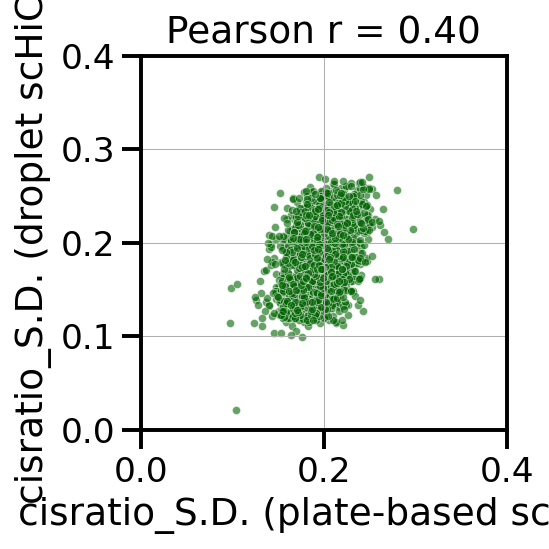

In [79]:
#comparison
# Step 1: Reset index of droplet dataframe to expose Bin_ID as a column
#use the selected bins to do comparision
droplet_all = droplet_all[droplet_all["total_counts_sum"] >= 2000] #iHep has fewer cells in droplet, so select < 500
plate_all   = plate_all[plate_all["total_counts_sum"] >= 1000]

droplet_df = droplet_all
plate_df   = plate_all


# Step 2: Merge on Bin_ID
merged = plate_df[['Bin_ID', 'cisratio_S.D.']].merge(
    droplet_df[['Bin_ID', 'cisratio_S.D.']],
    on='Bin_ID',
    suffixes=('_plated', '_droplet')
)

# Step 3: Clean up any NaNs or Infs
df_corr = merged.replace([np.inf, -np.inf], np.nan).dropna(subset=['cisratio_S.D._plated', 'cisratio_S.D._droplet'])

# Step 4: Extract clean x and y values
x_clean = df_corr['cisratio_S.D._plated']
y_clean = df_corr['cisratio_S.D._droplet']

# Step 5: Calculate Pearson correlation
from scipy.stats import pearsonr
corr_coef, p_value = pearsonr(x_clean, y_clean)

# Step 6: Plot
plt.figure(figsize=(4, 4), dpi=150)
sns.scatterplot(x=x_clean, y=y_clean, alpha=0.6, s=15, color='darkgreen')
plt.xlabel('cisratio_S.D. (plate-based scHiC)')
plt.ylabel('cisratio_S.D. (droplet scHiC)')
plt.xlim(0, 0.4)
plt.ylim(0, 0.4)
plt.title(f'Pearson r = {corr_coef:.2f}')
plt.grid(True, lw=0.5)
plt.tight_layout()

# Step 7: Save plot
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/sd_cistotal_across_plated(>0.3kb)VSdroplets(>0.4kb)_H1_filter_nocolor.pdf")
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/sd_cistotal_across_platedVSdroplets_H1_filter_nocolor>0.3kb.pdf")

plt.show()

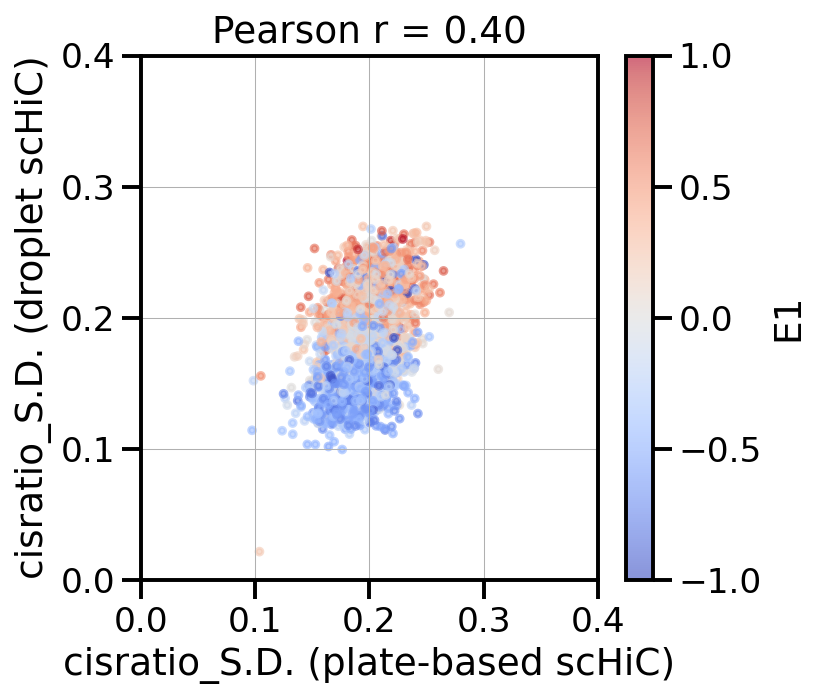

In [ ]:
# comparison
# Step 1: Reset index of droplet dataframe to expose Bin_ID as a column
# use the selected bins to do comparision
droplet_all = droplet_all[droplet_all["total_counts_sum"] >= 2000]  # iHep has fewer cells in droplet, so select < 500
plate_all   = plate_all[plate_all["total_counts_sum"] >= 1000]
droplet_df = droplet_all
plate_df   = plate_all

# Step 2: Merge on Bin_ID, carrying E1 from plate_df for coloring
merged = plate_df[['Bin_ID', 'cisratio_S.D.', 'E1']].merge(
    droplet_df[['Bin_ID', 'cisratio_S.D.']],
    on='Bin_ID',
    suffixes=('_plated', '_droplet')
)

# Step 3: Clean up any NaNs or Infs
df_corr = merged.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['cisratio_S.D._plated', 'cisratio_S.D._droplet', 'E1']
)

# Step 4: Extract clean x, y, and color values
x_clean = df_corr['cisratio_S.D._plated']
y_clean = df_corr['cisratio_S.D._droplet']
color_clean = df_corr['E1']

# Step 5: Calculate Pearson correlation
from scipy.stats import pearsonr
corr_coef, p_value = pearsonr(x_clean, y_clean)

# Step 6: Plot, colored by E1
plt.figure(figsize=(6, 5), dpi=150)
scatter = plt.scatter(
    x_clean, y_clean,
    c=color_clean, cmap='coolwarm', alpha=0.6, s=10,
    vmin=-1, vmax=1  # center colormap at 0 for E1's +/- compartment sign
)
cbar = plt.colorbar(scatter)
cbar.set_label('E1')
plt.xlabel('cisratio_S.D. (plate-based scHiC)')
plt.ylabel('cisratio_S.D. (droplet scHiC)')
plt.xlim(0, 0.4)
plt.ylim(0, 0.4)
plt.title(f'Pearson r = {corr_coef:.2f}')
plt.grid(True, lw=0.5)
plt.tight_layout()

# Step 7: Save plot
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/sd_cistotal_across_platedVSdroplets_H1_filter>0.3kb.pdf")
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/sd_cistotal_across_plated(>0.3kb)VSdroplets(>0.4kb)_H1_filter.pdf")
plt.show()

# plot the E1 VS cis/total.mean() colored by cis/total.s.d.() for droplet-HiC

Note:
In Fig 1, ES droplet HiC with filtering: contact dist>0.3kb 
In Fig 3, ES,DE,HB,iHep,mHep droplet HiC with filtering: contact dist>0.4kb to fairly compare different stages. 
(Reason: ES library size ~ 350bp; DE, HB, iHep,mHep library size ~250bp, distribution of singleton fragments size are different)

In [82]:
#create chrom_size df
chrom_size = {
    'chr1': '248956422',    'chr2': '242193529',
    'chr3': '198295559',    'chr4': '190214555',
    'chr5': '181538259',    'chr6': '170805979',
    'chr7': '159345973',    'chr8': '145138636',
    'chr9': '138394717',    'chr10': '133797422',
    'chr11': '135086622',    'chr12': '133275309',
    'chr13': '114364328',    'chr14': '107043718',
    'chr15': '101991189',    'chr16': '90338345',
    'chr17': '83257441',    'chr18': '80373285',
    'chr19': '58617616',    'chr20': '64444167',
    'chr21': '46709983',    'chr22': '50818468',
    'chrX': '156040895',    'chrY': '57227415'}

chrom_size_df = pd.DataFrame(list(chrom_size.items()), columns=['chrom', 'Size'])
# Convert the 'Size' column to integer type
chrom_size_df['Size'] = chrom_size_df ['Size'].astype(int)
chrom_size_df['normalized_ratio'] = sum(chrom_size_df['Size'])/chrom_size_df ['Size']

In [83]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [84]:
#apply 'split_df_by_chrom' function for dropletHiC

#dropletbased
#dropletHiC = droplet_comp_bin_cisratio_mHep.copy()
dropletHiC = droplet_comp_bin_cisratio_H1.copy()

dropletHiC = dropletHiC[dropletHiC["total_counts_sum"] >= 2000] #for ES, DE, HB, mHep cells I used 2000, for iHep cells I used 1000

# plate-based
#plate_all = plated_comp_bin_cisratio_mHep.reset_index().copy()
plate_all = plated_comp_bin_cisratio_H1.reset_index().copy()

plate_all   = plate_all[plate_all["total_counts_sum"] >= 1000]

comp_bin_chrom = split_df_by_chrom(dropletHiC)



In [ ]:
##plot the corelationship between cis/tota and EGV for droplet HiC
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import pearsonr
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_context("talk")

# Assume comp_bin_chrom is a dict: {chrom: df}
chrom_list = list(comp_bin_chrom.keys())

fig, axes = plt.subplots(nrows=len(chrom_list), ncols=1, figsize=(4, 75), dpi=150)

# Define normalizer for hue
#norm = mcolors.Normalize(vmin=0.1, vmax=0.4) #if filter > 0.4kb
norm = mcolors.Normalize(vmin=0.07, vmax=0.25) #if filter > 0.3kb

# Loop through chromosomes and plot
for j, chrom in enumerate(chrom_list):
    df = comp_bin_chrom[chrom].dropna()
    
    ax = axes[j]

    # Scatter with hue
    sns.scatterplot(
        data=df, x='E1', y='cisratio_mean', s=15,
        hue='cisratio_S.D.', palette='seismic', hue_norm=norm,
        legend=False, ax=ax
    )

    # Regression line
    sns.regplot(
        data=df, x='E1', y='cisratio_mean',
        scatter=False, color='black', line_kws={'linewidth': 1}, ax=ax
    )

    ax.set_xlabel('E1', fontsize=8)
    ax.set_ylabel('cisratio_mean', fontsize=8)
    ax.set_title(f'(Chromosome: {chrom})', fontsize=10)
    ax.set_ylim(0.3, 1)
#    ax.set_ylim(0.85, 1)
    ax.set_xlim(-1.1, 1.1)

    # Pearson correlation
    corr_coeff = df['E1'].corr(df['cisratio_mean'])
    ax.annotate(f"Pearson r = {corr_coeff:.2f}", xy=(0.95, 0.8), xycoords='axes fraction', fontsize=10, ha='right')

    # Add colorbar
    sm = cm.ScalarMappable(cmap='seismic', norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', shrink=0.5, pad=0.02)
    cbar.set_label('cisratio_S.D.', fontsize=6)
    cbar.ax.tick_params(labelsize=8)

    # Tick label size
    ax.tick_params(axis='both', which='major', labelsize=8)

# Save and show
plt.tight_layout()
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/DropletHiC_S.D._cisratio_VS_EGV_dropletHiC_mHep_filter<0.4kb.pdf", format="pdf", bbox_inches="tight")
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/DropletHiC_S.D._cisratio_VS_EGV_dropletHiC_ES_filter<0.3kb.pdf", format="pdf", bbox_inches="tight")

plt.show()

# plot the S.D. and mean of cis/total for chr2 

Note: use ES droplet HiC dataset with filtering: contact dist.> 0.3kb to plot tracks in Fig 1 

In [88]:
dropletHiC = droplet_comp_bin_cisratio_H1.copy()
dropletHiC = dropletHiC[dropletHiC["total_counts_sum"] >= 2000] #for ES, DE, HB, mHep cells I used 2000, for iHep cells I used 1000
dropletHiC

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.579389,0.208921,0.360589,11.221172,5936.0
chr1_Bin1,chr1,1000000,2000000,0.827367,0.662800,0.244899,0.369491,7.347107,3556.0
chr1_Bin2,chr1,2000000,3000000,0.503929,0.688600,0.243636,0.353813,5.024631,2040.0
chr1_Bin3,chr1,3000000,4000000,0.436396,0.669554,0.245251,0.366291,6.500000,3003.0
chr1_Bin4,chr1,4000000,5000000,0.291384,0.715502,0.225935,0.315772,9.355180,4425.0
...,...,...,...,...,...,...,...,...,...
chrY_Bin14,chrY,14000000,15000000,-0.374329,0.756672,0.217221,0.287074,7.517084,3300.0
chrY_Bin15,chrY,15000000,16000000,-0.242674,0.739502,0.226208,0.305892,7.703786,3459.0
chrY_Bin16,chrY,16000000,17000000,-0.187588,0.783359,0.210318,0.268483,7.150718,2989.0


Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/cisratio_s.d._droplet_based_chr2_ES>0.3kb.pdf


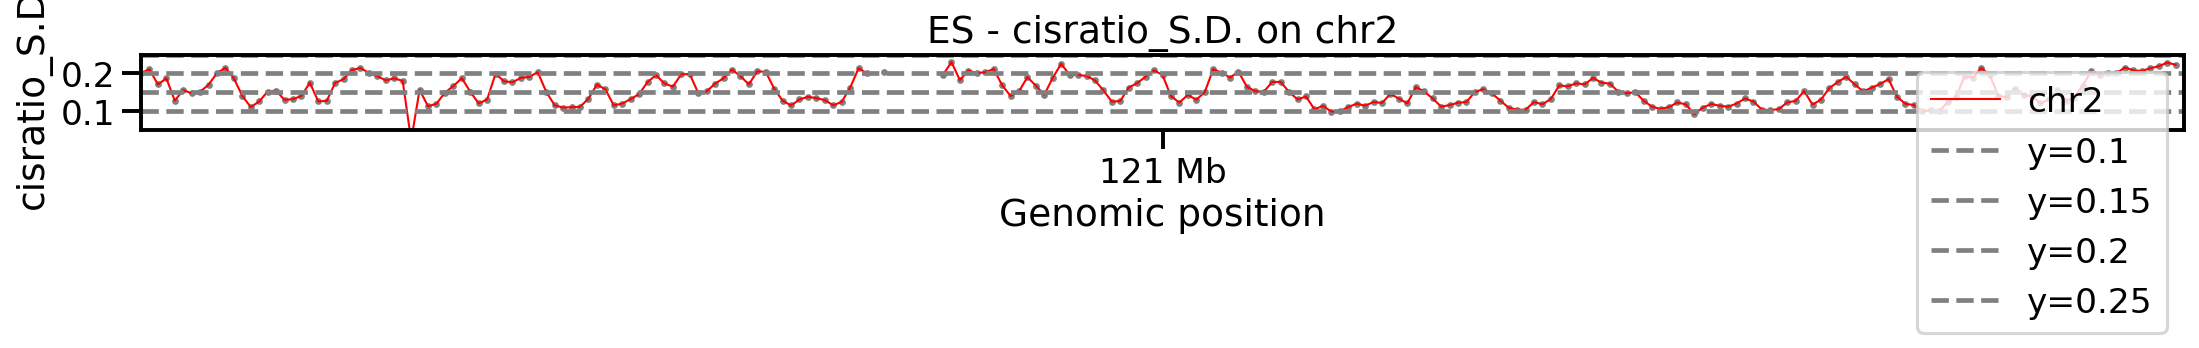

In [94]:
# Setup
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
chroms_to_plot = ['chr2']  # Only chr2
formatter = EngFormatter('b')
df = dropletHiC
# remove value of 'cistota_cv' when 'E1' is nan rows
df.loc[df['E1'].isna(), 'cisratio_S.D.'] = np.nan
# 2. If cisratio_cv > 0.4 → set to NaN
df.loc[df['cisratio_S.D.'] > 0.4, 'cisratio_S.D.'] = np.nan
# Compute chromosome offset
offsets = {}
current_offset = 0
chrom_boundaries = []
chrom_ticks = []
chrom_labels = []
for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom]
    chrom_start = chrom_df['start'].min()
    chrom_end = chrom_df['end'].max()
    chrom_size = chrom_end - chrom_start
    offsets[chrom] = current_offset
    chrom_boundaries.append((chrom, current_offset, current_offset + chrom_size))
    chrom_ticks.append(current_offset + chrom_size // 2)
    chrom_labels.append(chrom)
    current_offset += chrom_size
# Plot
fig, ax = plt.subplots(figsize=(15, 2), dpi=150)
for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom].copy()
    offset = offsets[chrom]
    chrom_df['offset_pos'] = chrom_df['start'] + offset
    ax.plot(chrom_df['offset_pos'], chrom_df['cisratio_S.D.'], color='red', lw=1, label=chrom)
    ax.scatter(chrom_df['offset_pos'], chrom_df['cisratio_S.D.'], color='grey', s=3)
# Formatting
for y_val in [0.1, 0.15, 0.2, 0.25]:
    ax.axhline(y=y_val, color='grey', linestyle='--', label=f'y={y_val}')
ax.set_xticks(chrom_ticks)
ax.set_xticklabels(chrom_labels)
ax.xaxis.set_major_formatter(formatter)
ax.set_ylabel('cisratio_S.D.')
ax.set_xlabel('Genomic position')
ax.set_title(f"ES - cisratio_S.D. on chr2")
ax.set_ylim(0.05, 0.25)
ax.set_xlim(0, current_offset)
ax.margins(x=0, y=0)
ax.legend(loc='upper right')
plt.tight_layout()
save_path = os.path.join(save_dir, f"cisratio_s.d._droplet_based_chr2_ES>0.3kb.pdf")
plt.savefig(save_path, format="pdf", bbox_inches="tight")
print(f"Saved: {save_path}")
plt.show()

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/cisratio_mean_droplet_based_chr2_ES>0.3kb.pdf


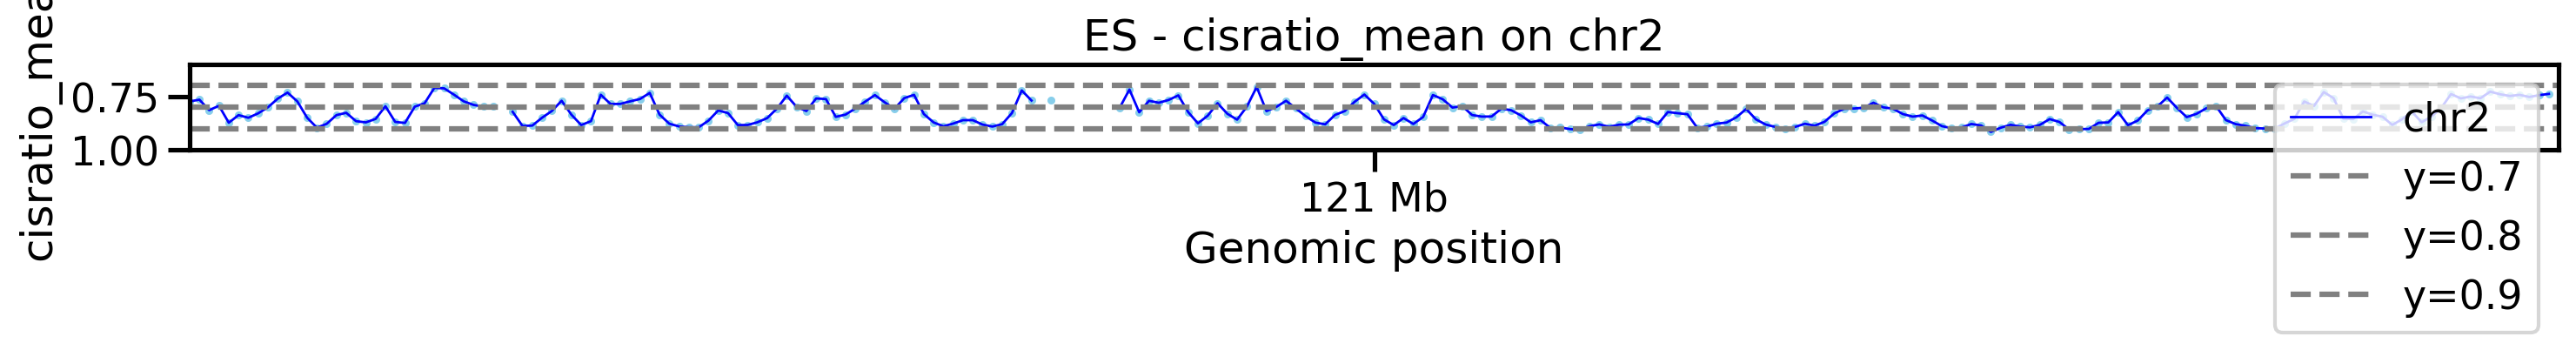

In [98]:
# Plot mean curve with standard deviation (S.D.) - chr2 only
# Setup
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
chroms_to_plot = ['chr2']  # Only plot chr2
formatter = EngFormatter('b')

df = dropletHiC
#remove value of 'cistota_cv' when 'E1' is nan rows
df.loc[df['E1'].isna(), 'cisratio_mean'] = np.nan
# 2. If cisratio_mean < 0.4 → set to NaN
df.loc[df['cisratio_mean'] < 0.4, 'cisratio_mean'] = np.nan


# Compute chromosome offsets for continuous x-axis
offsets = {}
current_offset = 0
chrom_boundaries = []
chrom_ticks = []
chrom_labels = []

for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom]
    chrom_start = chrom_df['start'].min()
    chrom_end = chrom_df['end'].max()
    chrom_size = chrom_end - chrom_start

    offsets[chrom] = current_offset
    chrom_boundaries.append((chrom, current_offset, current_offset + chrom_size))
    chrom_ticks.append(current_offset + chrom_size // 2)
    chrom_labels.append(chrom)

    current_offset += chrom_size

# Plot
fig, ax = plt.subplots(figsize=(15, 2), dpi=200)

for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom].copy()
    offset = offsets[chrom]
    chrom_df['offset_pos'] = chrom_df['start'] + offset

    ax.plot(chrom_df['offset_pos'], chrom_df['cisratio_mean'], color='blue', lw=1, label=chrom)
    ax.scatter(chrom_df['offset_pos'], chrom_df['cisratio_mean'], color='skyblue', s=3)

# Formatting
for y_val in [0.7, 0.8, 0.9]:
    ax.axhline(y=y_val, color='grey', linestyle='--', label=f'y={y_val}')
ax.set_xticks(chrom_ticks)
ax.set_xticklabels(chrom_labels)
ax.xaxis.set_major_formatter(formatter)

ax.set_ylabel('cisratio_mean')
ax.set_xlabel('Genomic position')
ax.set_title(f"ES - cisratio_mean on chr2")
ax.set_ylim(0.6, 1.0)
ax.set_ylim(ax.get_ylim()[::-1])  # Reverse y-axis
ax.set_xlim(0, current_offset)
ax.margins(x=0, y=0)
ax.legend(loc='upper right')

plt.tight_layout()
save_path = os.path.join(save_dir, f"cisratio_mean_droplet_based_chr2_ES>0.3kb.pdf")

plt.savefig(save_path, format="pdf", bbox_inches="tight")
print(f"Saved: {save_path}")
plt.show()

# Plot all cis/total S.D. across all stages (chr2 + chr11)

Note: use ES,DE,HB,iHep,mHep droplet HiC dataset with filtering: contact dist.> 0.4kb to plot tracks in Fig 3 

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/cisratio_sd_droplet_H1_chr2_chr11.pdf


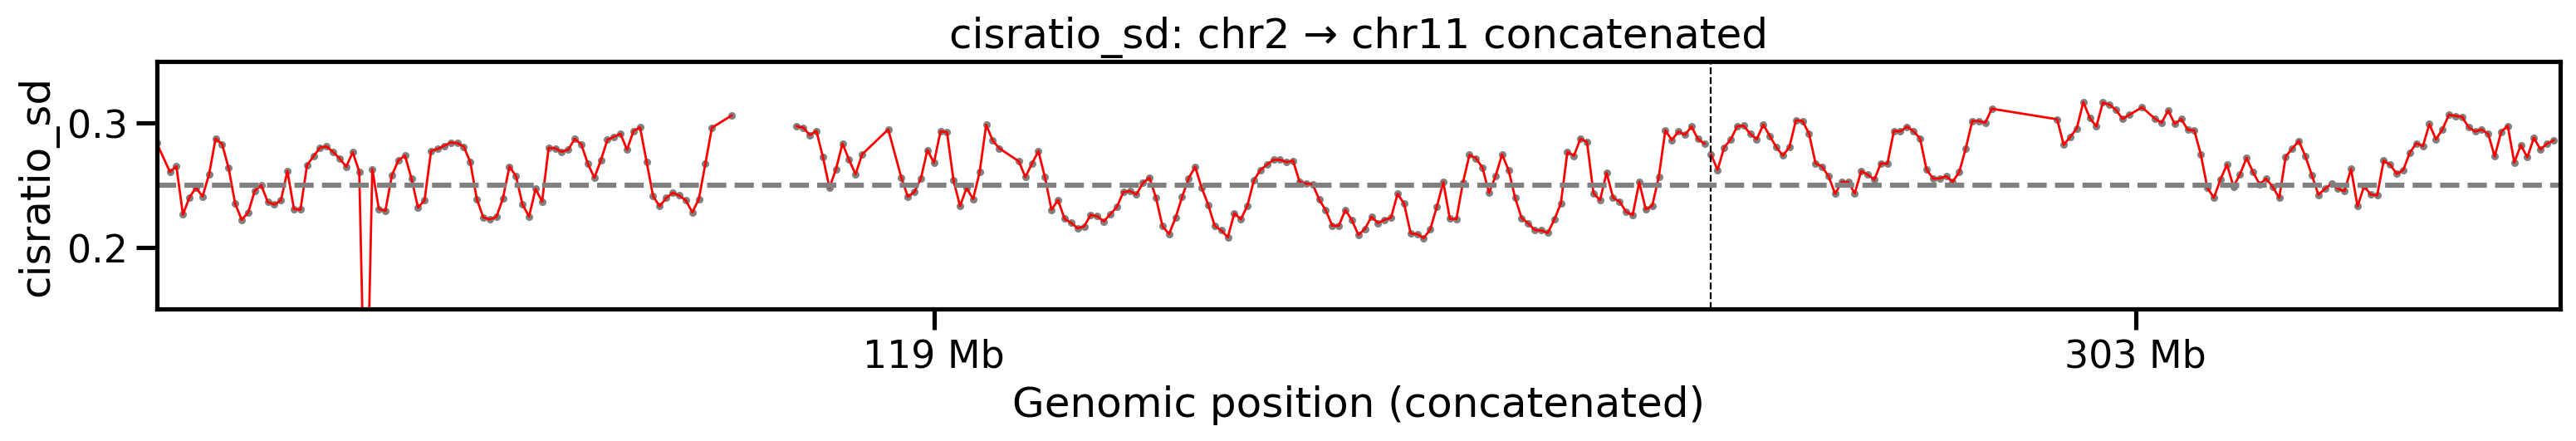

In [ ]:
# Plot all cis/total S.D. across all stages (chr2 + chr11 only)--> use filter > 0.4kb for all five stages
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
chroms_to_plot = ['chr2', 'chr11']   # chromosomes in order
formatter = EngFormatter('b')

df = dropletHiC
#remove value of 'cistota_cv' when 'E1' is nan rows
df.loc[df['E1'].isna(), 'cisratio_S.D.'] = np.nan
# 2. If cisratio_cv > 0.6 → set to NaN
df.loc[df['cisratio_S.D.'] > 0.4, 'cisratio_S.D.'] = np.nan

# Compute offsets (concatenate chromosomes)
offsets = {}
current_offset = 0
chrom_boundaries = []
chrom_ticks = []
chrom_labels = []

for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom]
    chrom_start = chrom_df['start'].min()
    chrom_end   = chrom_df['end'].max()
    chrom_size  = chrom_end - chrom_start

    offsets[chrom] = current_offset

    # boundary for dashed line
    chrom_boundaries.append(current_offset)

    # midpoint for tick
    chrom_ticks.append(current_offset + chrom_size // 2)
    chrom_labels.append(chrom)

    current_offset += chrom_size

# --- Plot ---
fig, ax = plt.subplots(figsize=(16, 3), dpi=200)

for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom].copy()

    offset = offsets[chrom]
    chrom_start = chrom_df['start'].min()

    # Offset positions so chr11 follows chr2
    chrom_df["offset_pos"] = (chrom_df["start"] - chrom_start) + offset

    ax.plot(
        chrom_df["offset_pos"],
        chrom_df["cisratio_S.D."],
        color="red",
        lw=1
    )
    ax.scatter(
        chrom_df["offset_pos"],
        chrom_df["cisratio_S.D."],
        color="grey",
        s=3
    )

# --- Draw dashed vertical lines between chromosomes ---
# Skip the first boundary (0)
for boundary in chrom_boundaries[1:]:
    ax.axvline(x=boundary, color="black", linestyle="--", lw=0.8)

# --- Formatting ---
ax.axhline(y=0.25, color='grey', linestyle='--')
ax.set_ylabel("cisratio_sd")
ax.set_xlabel("Genomic position (concatenated)")
ax.set_ylim(0.15, 0.35)
ax.set_xlim(0, current_offset)

# Chromosome labels at center of each region
ax.set_xticks(chrom_ticks)
ax.set_xticklabels(chrom_labels)

ax.xaxis.set_major_formatter(formatter)

ax.set_title("cisratio_sd: chr2 → chr11 concatenated")

plt.tight_layout()

save_path = os.path.join(save_dir, "cisratio_sd_droplet_H1_chr2_chr11.pdf")
plt.savefig(save_path, format="pdf", bbox_inches="tight")
print("Saved:", save_path)

plt.show()

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/cisratio_mean_droplet_chr2_chr11_ES.pdf


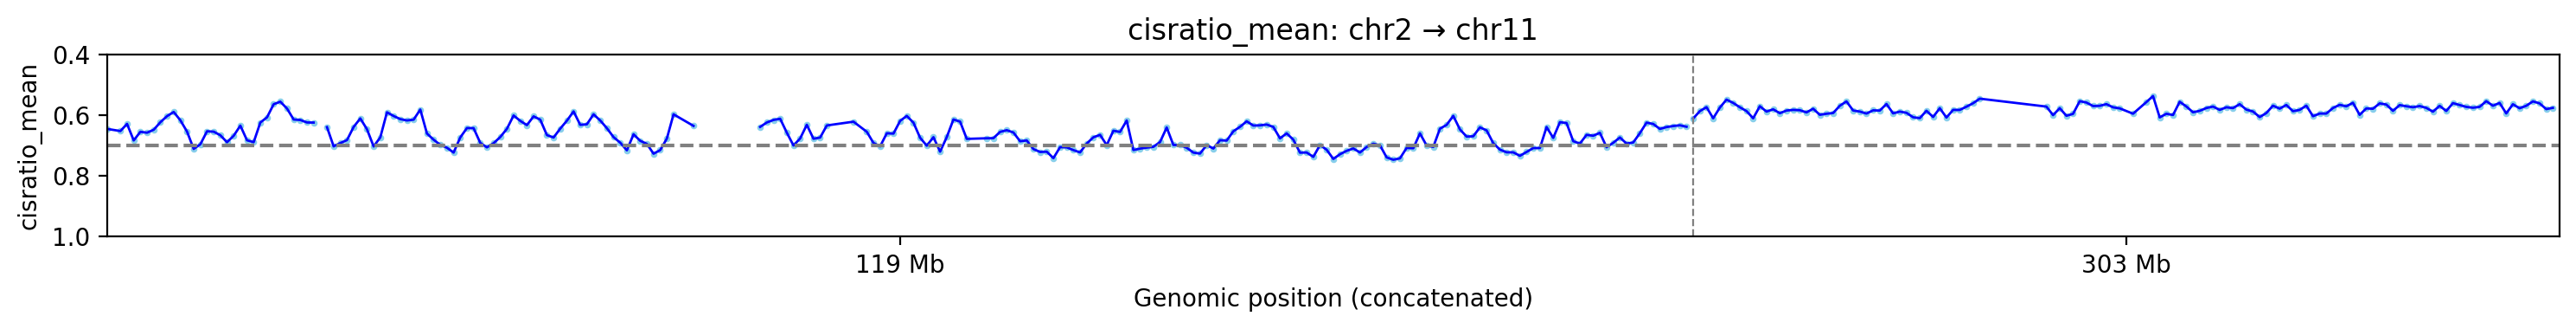

In [13]:
# Plot mean curve with standard deviation (S.D.) - chr2 and chr11 only
# Setup
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
chroms_to_plot = ['chr2', 'chr11']  # Now plot chr2 and chr11
formatter = EngFormatter('b')

df = dropletHiC
#remove value of 'cistota_cv' when 'E1' is nan rows
df.loc[df['E1'].isna(), 'cisratio_mean'] = np.nan
# 2. If cisratio_mean < 0.4 → set to NaN
df.loc[df['cisratio_mean'] < 0.4, 'cisratio_mean'] = np.nan


# Compute chromosome offsets for continuous x-axis
offsets = {}
current_offset = 0
chrom_boundaries = []
chrom_ticks = []
chrom_labels = []

for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom]

    chrom_start = chrom_df['start'].min()
    chrom_end   = chrom_df['end'].max()
    chrom_size  = chrom_end - chrom_start

    offsets[chrom] = current_offset
    chrom_boundaries.append(current_offset)     # store boundary
    chrom_ticks.append(current_offset + chrom_size // 2)
    chrom_labels.append(chrom)

    current_offset += chrom_size

# Plot
fig, ax = plt.subplots(figsize=(15, 2), dpi=200)

for chrom in chroms_to_plot:
    chrom_df = df[df['chrom'] == chrom].copy()

    offset = offsets[chrom]
    chrom_start = chrom_df['start'].min()

    # Offset each chromosome so chr11 follows chr2
    chrom_df['offset_pos'] = (chrom_df['start'] - chrom_start) + offset

    # Plot
    ax.plot(
        chrom_df['offset_pos'],
        chrom_df['cisratio_mean'],
        color='blue', lw=1
    )
    ax.scatter(
        chrom_df['offset_pos'],
        chrom_df['cisratio_mean'],
        color='skyblue', s=3
    )

# Add dashed boundary lines between chromosomes
for boundary in chrom_boundaries[1:]:  # skip first (0)
    ax.axvline(x=boundary, color='gray', linestyle='--', lw=0.8)

# Formatting
ax.axhline(y=0.7, color='gray', linestyle='--')
ax.set_xticks(chrom_ticks)
ax.set_xticklabels(chrom_labels)
ax.xaxis.set_major_formatter(formatter)

ax.set_ylabel('cisratio_mean')
ax.set_xlabel('Genomic position (concatenated)')
ax.set_title("cisratio_mean: chr2 → chr11")

ax.set_ylim(0.4, 1.0)
ax.set_ylim(ax.get_ylim()[::-1])  # Reverse y-axis
ax.set_xlim(0, current_offset)

ax.margins(x=0, y=0)

plt.tight_layout()

save_path = os.path.join(save_dir, "cisratio_mean_droplet_chr2_chr11_ES.pdf")
plt.savefig(save_path, format="pdf", bbox_inches="tight")
print("Saved:", save_path)

plt.show()

# histgram of overall folding variability

Note, see above we used ES,DE,HB,iHep,mHep droplet HiC dataset with filtering contact dist.> 0.4kb to do comparison in Fig3

In [60]:
#load data
droplet_comp_bin_cisratio_H1 = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_H1_comp_bin_cisratio_filter<0.4kb.txt', sep='\t',index_col=0)
droplet_comp_bin_cisratio_DE = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_DE_comp_bin_cisratio_filter<0.4kb.txt', sep='\t',index_col=0)
droplet_comp_bin_cisratio_HB = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_HB_comp_bin_cisratio_filter<0.4kb.txt', sep='\t',index_col=0)
droplet_comp_bin_cisratio_iHep = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_iHep_comp_bin_cisratio_filter<0.4kb.txt', sep='\t',index_col=0)
droplet_comp_bin_cisratio_mHep = pd.read_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/dropletHiC_mHep_comp_bin_cisratio_filter<0.4kb.txt', sep='\t',index_col=0)

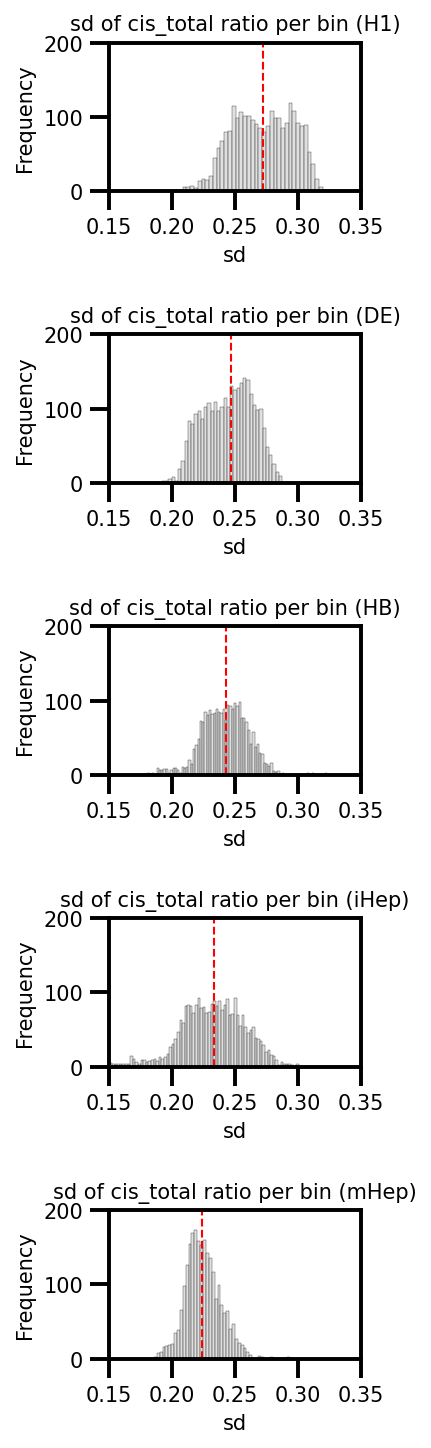

In [61]:
# Copy the dataframes
droplet_H1  = droplet_comp_bin_cisratio_H1.copy()
droplet_DE = droplet_comp_bin_cisratio_DE.copy()
droplet_HB = droplet_comp_bin_cisratio_HB.copy()
droplet_iHep = droplet_comp_bin_cisratio_iHep.copy()
droplet_mHep = droplet_comp_bin_cisratio_mHep.copy()

droplet_H1  = droplet_H1[droplet_H1["total_counts_sum"] >= 2000]
droplet_DE  = droplet_DE[droplet_DE["total_counts_sum"] >= 2000]
droplet_HB  = droplet_HB[droplet_HB["total_counts_sum"] >= 2000]
droplet_iHep  = droplet_iHep[droplet_iHep["total_counts_sum"] >= 1000] #used 1000 since the cell counts iHep is too few
droplet_mHep = droplet_mHep[droplet_mHep["total_counts_sum"] >= 2000]

#droplet_H1  = droplet_H1[droplet_H1["total_counts_sum"] >= 500]
#droplet_DE  = droplet_DE[droplet_DE["total_counts_sum"] >= 500]
#droplet_HB  = droplet_HB[droplet_HB["total_counts_sum"] >= 500]
#droplet_iHep  = droplet_iHep[droplet_iHep["total_counts_sum"] >= 500] #used 1000 since the cell counts iHep is too few
#droplet_mHep = droplet_mHep[droplet_mHep["total_counts_sum"] >= 500]

# Put them into a dict for easy iteration
datasets = {
    "H1": droplet_H1,
    "DE": droplet_DE,
    "HB": droplet_HB,
    "iHep": droplet_iHep,
    "mHep": droplet_mHep
}

# Set up subplots: 2 rows, 1 column
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(3, 10), dpi=150)

for i, (stage, df) in enumerate(datasets.items()):
#    median = df['cisratio_cv'].median()
    median = df['cisratio_S.D.'].median()
#    median = df['cisratio_IQR'].median()

    # Plot histogram
    sns.histplot(
#        df['cisratio_cv'], bins=100, kde=False,
        df['cisratio_S.D.'], bins=100, kde=False,
#        df['cisratio_IQR'], bins=100, kde=False,
        color='lightgrey', alpha=0.7, ax=axes[i]
    )

    # Set axis limits
#    axes[i].set_xlim(0.15, 0.65)
    axes[i].set_xlim(0.15, 0.35)
    axes[i].set_ylim(0, 200)

    # Add median line
    axes[i].axvline(x=median, color='red', linestyle='--', lw=1)

    # Titles & labels
#    axes[i].set_title(f'cv of cis_total ratio per bin ({stage})', fontsize=10)
    axes[i].set_title(f'sd of cis_total ratio per bin ({stage})', fontsize=10)
#    axes[i].set_title(f'IQR of cis_total ratio per bin ({stage})', fontsize=10)
#    axes[i].set_xlabel('cv', fontsize=10)
    axes[i].set_xlabel('sd', fontsize=10)
#    axes[i].set_xlabel('IQR', fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    axes[i].tick_params(axis='both', which='major', labelsize=10)

# Adjust layout
plt.tight_layout()

# Save to PDF
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_cv_perbin_5stages.pdf",format="pdf", bbox_inches="tight")
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_sd_perbin_5stages.pdf",format="pdf", bbox_inches="tight")
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_IQR_perbin_5stages.pdf",format="pdf", bbox_inches="tight")
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_s.d._perbin_5stages>0.4kb.pdf",format="pdf", bbox_inches="tight")


#plt.show()


In [63]:
#organize droplet HiC table
droplet_H1  = droplet_comp_bin_cisratio_H1.copy()
droplet_DE = droplet_comp_bin_cisratio_DE.copy()
droplet_HB = droplet_comp_bin_cisratio_HB.copy()
droplet_iHep = droplet_comp_bin_cisratio_iHep.copy()
droplet_mHep = droplet_comp_bin_cisratio_mHep.copy()


dropletHiC = {
    "ES": droplet_H1,      
    "DE": droplet_DE,
    "HB": droplet_HB,
    "iHep": droplet_iHep,
    "mHep": droplet_mHep
}

In [62]:
#organize plate-based HiC table
plated_H1  = plated_comp_bin_cisratio_H1.copy()
plated_DE = plated_comp_bin_cisratio_DE.copy()
plated_HB = plated_comp_bin_cisratio_HB.copy()
plated_iHep = plated_comp_bin_cisratio_iHep.copy()
plated_mHep = plated_comp_bin_cisratio_mHep.copy()


platebasedHiC = {
    "ES": plated_H1,      
    "DE": plated_DE,
    "HB": plated_HB,
    "iHep": plated_iHep,
    "mHep": plated_mHep
}

In [74]:
platebasedHiC['ES']['cisratio_S.D.'].median()

0.197005445835233

# plot the 10 loci used in DNA FISH probe

In [64]:
#select the 10 loci informations into a dictionary
# Base directory for saving results
base_dir = '/home/xiangru.huo-umw/scHiC/scripts/plot2/'
os.makedirs(base_dir, exist_ok=True)

# Stages
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

# 10 loci groups
loci_list = [
    ['chr2_Bin2', 'chr2_Bin3'],
    ['chr2_Bin100', 'chr2_Bin101'],
    ['chr2_Bin153', 'chr2_Bin154'],
    ['chr11_Bin11'],
    ['chr11_Bin88'],
    ['chr11_Bin107', 'chr11_Bin108'],
    ['chr2_Bin79', 'chr2_Bin80', 'chr2_Bin81', 'chr2_Bin82', 'chr2_Bin83'],
    ['chr11_Bin41'],
    ['chr2_Bin32'],
    ['chr11_Bin119']
]

# Dictionary to store all results
loci_organized = {}

# Process 10 loci groups
for i in range(10):
    loci = loci_list[i]
    selected_tables = []

    for stage in stages:
        df = dropletHiC[stage].copy()

        # Select matching bins
        df_select = df[df.index.isin(loci)].copy()
        df_select['stage'] = stage

        selected_tables.append(df_select)

    # Combine across stages
    loci_organized[i] = pd.concat(selected_tables, ignore_index=True)

    # Build filename based on loci names
    loci_str = "_".join(loci)
    filename = f"DNAFISHloci_info_{loci_str}_dropletHiC.csv"
    file_path = os.path.join(base_dir, filename)

    # Save
    loci_organized[i].to_csv(file_path, index=False)

    print(f"Saved {file_path}")

Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin2_chr2_Bin3_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin100_chr2_Bin101_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin153_chr2_Bin154_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin11_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin88_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin107_chr11_Bin108_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin41_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin32_dropletHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin119_drople

In [65]:
#read these files
# Define the base directory
base_dir = '/home/xiangru.huo-umw/scHiC/scripts/plot2/'

# Find all matching CSV files
csv_files = [
    f for f in os.listdir(base_dir)
    if f.startswith("DNAFISHloci_info_") and f.endswith("_dropletHiC.csv")
]

# Dictionary to store each locus table
loci_data = {}

for file in csv_files:
    file_path = os.path.join(base_dir, file)
    df = pd.read_csv(file_path)

    # Extract the locus key (everything between the prefix and suffix)
    loci_key = (
        file
        .replace("DNAFISHloci_info_", "")
        .replace("_dropletHiC.csv", "")
    )

    loci_data[loci_key] = df
    print(f"Loaded: {file}")

print("\nAll loci files have been loaded into loci_data.")

Loaded: DNAFISHloci_info_chr2_Bin2_chr2_Bin3_dropletHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin100_chr2_Bin101_dropletHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin153_chr2_Bin154_dropletHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin11_dropletHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin88_dropletHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin107_chr11_Bin108_dropletHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83_dropletHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin41_dropletHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin32_dropletHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin119_dropletHiC.csv

All loci files have been loaded into loci_data.


Saved: /home/xiangru.huo-umw/scHiC/scripts/plot2/Cistotal_mean_S.D._10loci2_dropletbased.pdf


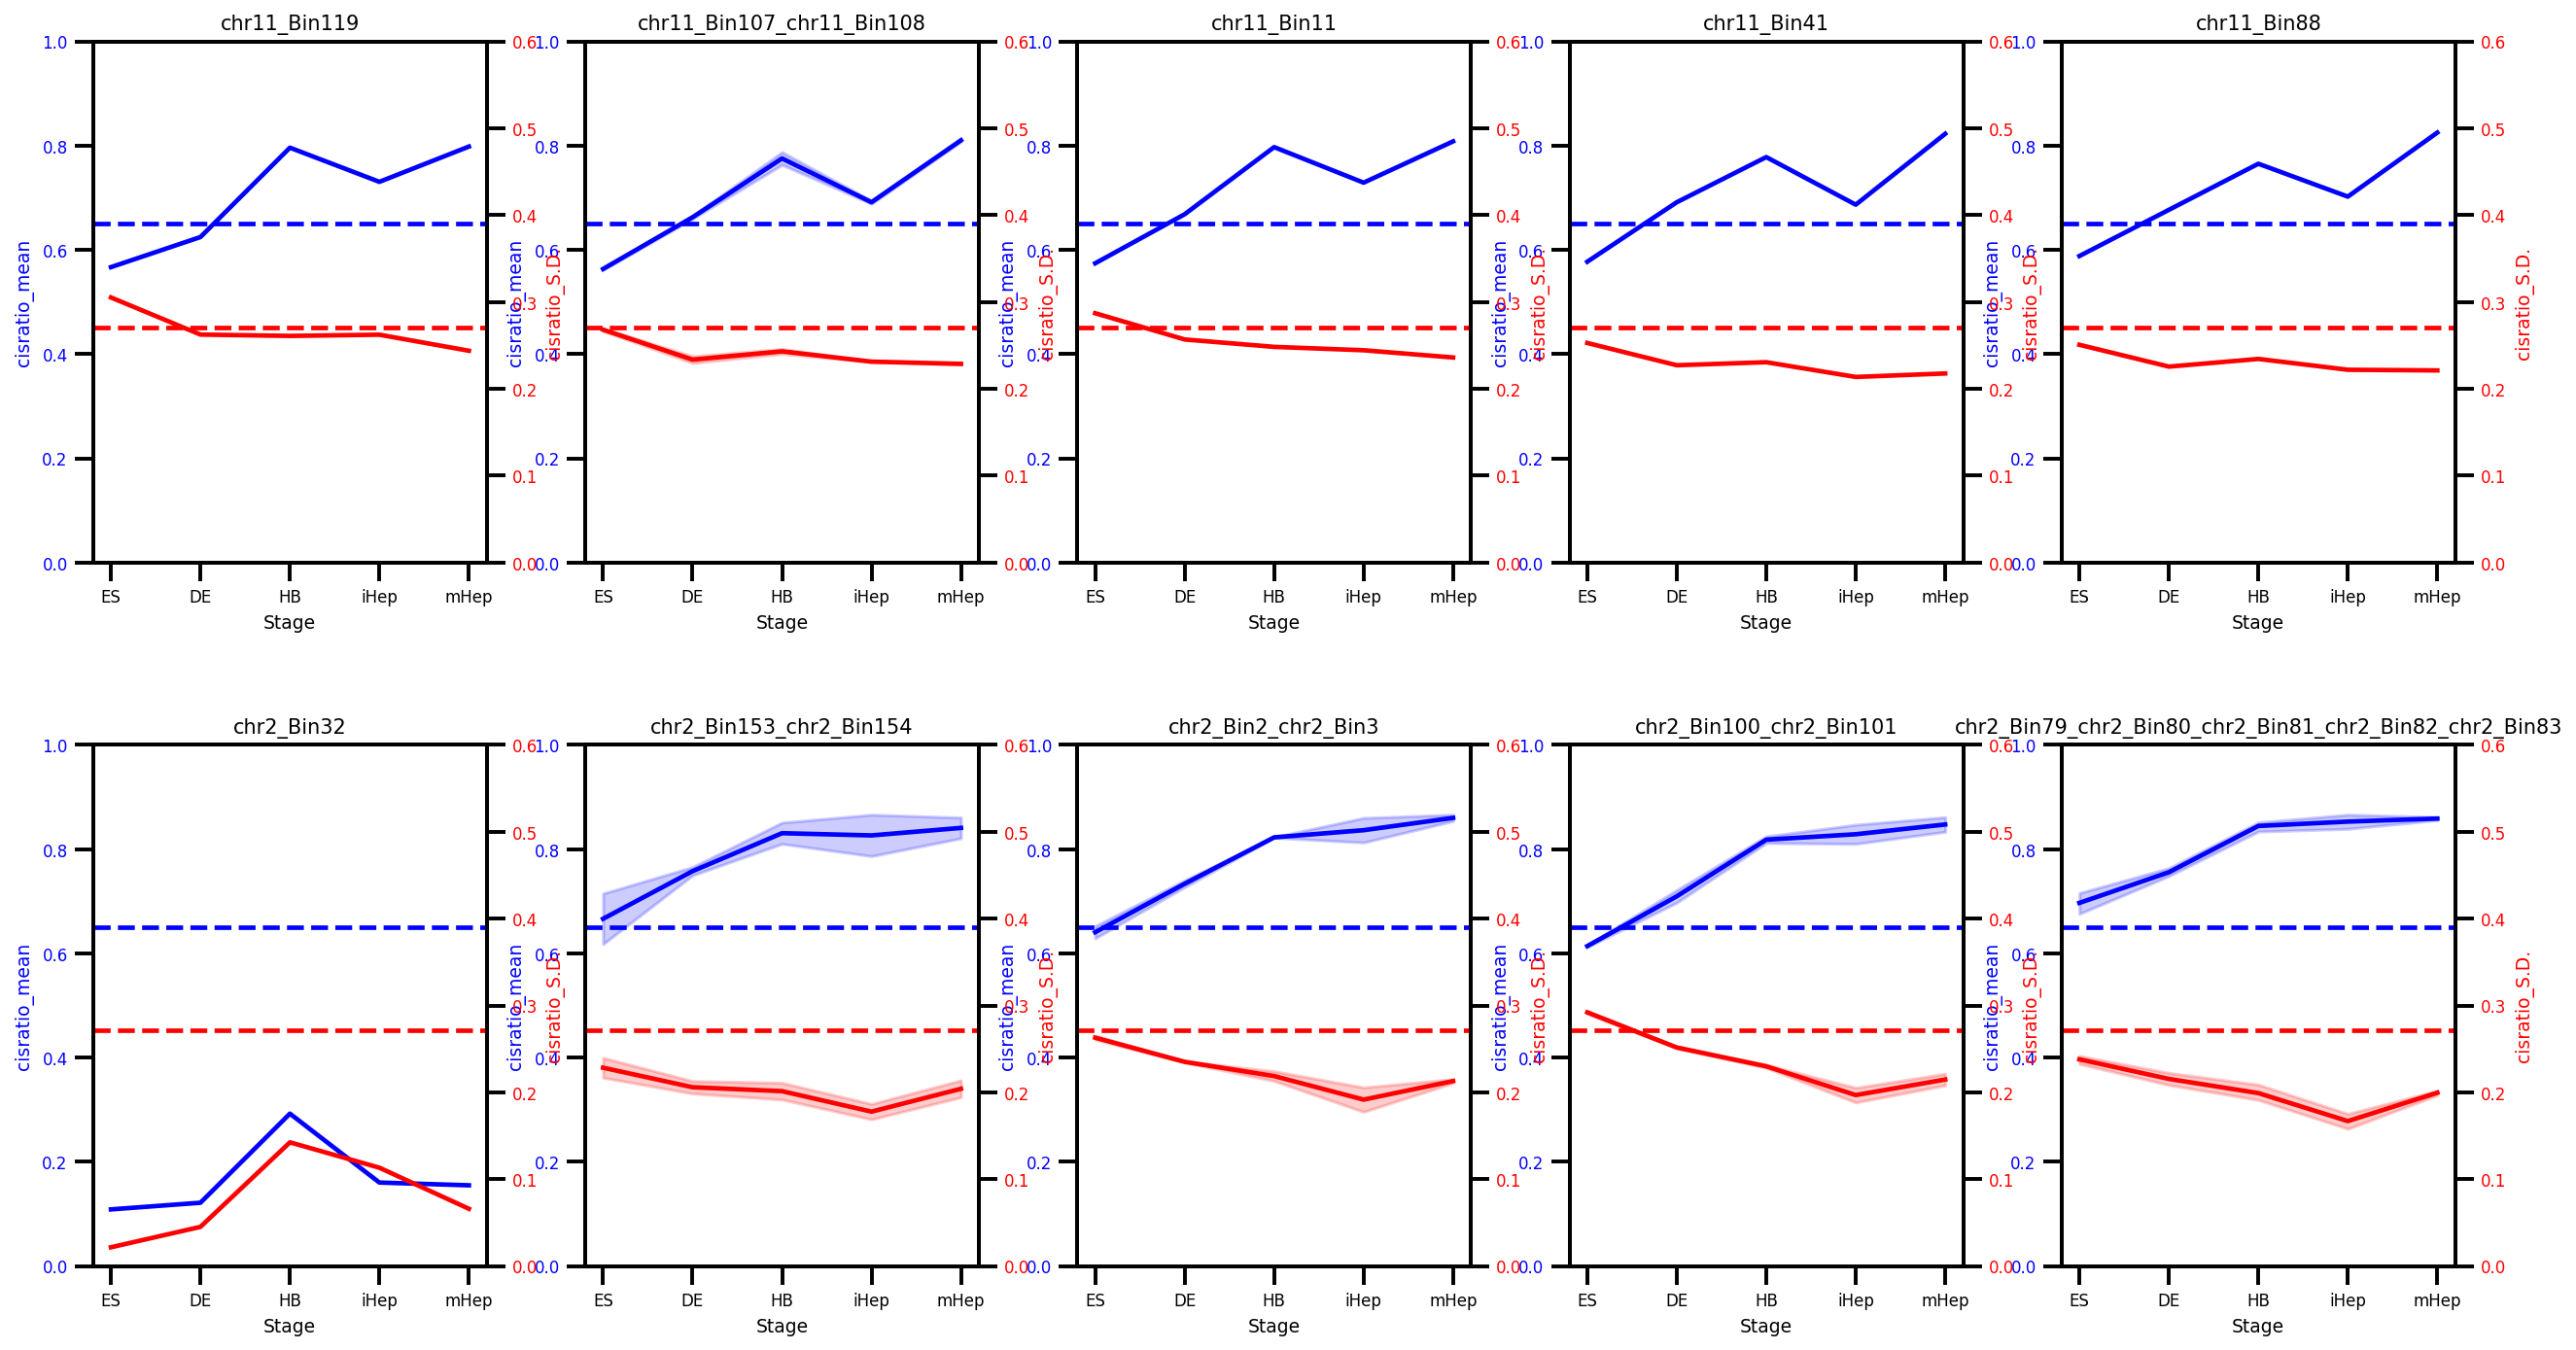

In [ ]:
# Define the two groups of loci
first_line = [
    'chr11_Bin119', 'chr11_Bin107_chr11_Bin108', 'chr11_Bin11',
    'chr11_Bin41', 'chr11_Bin88'
]
second_line = [
    'chr2_Bin32', 'chr2_Bin153_chr2_Bin154', 'chr2_Bin2_chr2_Bin3',
    'chr2_Bin100_chr2_Bin101',
    'chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83'
]

# Bigger figure + not too tight DPI
fig, axes = plt.subplots(
    nrows=2, ncols=5,
    figsize=(18, 10),   # <-- bigger figure
    dpi=150,
    sharex=False
)

# Helper function to plot each row
def plot_row(row_axes, loci_list):
    for col, locus in enumerate(loci_list):
        ax1 = row_axes[col]

        if locus not in loci_data:
            ax1.set_visible(False)
            continue

        data = loci_data[locus].copy()
        data.replace([np.inf, -np.inf], np.nan, inplace=True)
        data['cisratio_S.D.'] = pd.to_numeric(data['cisratio_S.D.'], errors='coerce')

        ax2 = ax1.twinx()

        # cisratio_mean (blue)
        sns.lineplot(data=data, x='stage', y='cisratio_mean',
                     ax=ax1, color="blue")
        ax1.axhline(y=0.65, color='blue', linestyle='--')
        ax1.set_ylim(0, 1)
        ax1.set_ylabel("cisratio_mean", color="blue", fontsize=9)
        ax1.tick_params(axis='y', labelcolor='blue', labelsize=8)

        # cisratio_SD (red)
        sns.lineplot(data=data, x='stage', y='cisratio_S.D.',
                     ax=ax2, color="red")
        ax2.axhline(y=0.271, color='red', linestyle='--')
        ax2.set_ylim(0, 0.6)
        ax2.set_ylabel("cisratio_S.D.", color="red", fontsize=9)
        ax2.tick_params(axis='y', labelcolor='red', labelsize=8)

        ax1.set_title(locus, fontsize=10)
        ax1.set_xlabel("Stage", fontsize=9)
        ax1.tick_params(axis='x', labelsize=8)

# Plot two lines
plot_row(axes[0, :], first_line)
plot_row(axes[1, :], second_line)

# Add spacing between subplots
plt.subplots_adjust(
    left=0.07, right=0.97,
    top=0.92, bottom=0.08,
    wspace=0.25,   # spacing between columns
    hspace=0.35    # spacing between rows
)

# Save figure
plot_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Cistotal_mean_S.D._10loci2_dropletbased.pdf"
#plt.savefig(plot_path, format="pdf", bbox_inches="tight")
print("Saved:", plot_path)

plt.show()

In [67]:
#plate-based
#select the 10 loci informations into a dictionary
# Base directory for saving results
base_dir = '/home/xiangru.huo-umw/scHiC/scripts/plot2/'
os.makedirs(base_dir, exist_ok=True)

# Stages
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

# 10 loci groups
loci_list = [
    ['chr2_Bin2', 'chr2_Bin3'],
    ['chr2_Bin100', 'chr2_Bin101'],
    ['chr2_Bin153', 'chr2_Bin154'],
    ['chr11_Bin11'],
    ['chr11_Bin88'],
    ['chr11_Bin107', 'chr11_Bin108'],
    ['chr2_Bin79', 'chr2_Bin80', 'chr2_Bin81', 'chr2_Bin82', 'chr2_Bin83'],
    ['chr11_Bin41'],
    ['chr2_Bin32'],
    ['chr11_Bin119']
]

# Dictionary to store all results
loci_organized = {}

# Process 10 loci groups
for i in range(10):
    loci = loci_list[i]
    selected_tables = []

    for stage in stages:
        df = platebasedHiC[stage].copy()

        # Select matching bins
        df_select = df[df.index.isin(loci)].copy()
        df_select['stage'] = stage

        selected_tables.append(df_select)

    # Combine across stages
    loci_organized[i] = pd.concat(selected_tables, ignore_index=True)

    # Build filename based on loci names
    loci_str = "_".join(loci)
    filename = f"DNAFISHloci_info_{loci_str}_platebasedHiC.csv"
    file_path = os.path.join(base_dir, filename)

    # Save
    loci_organized[i].to_csv(file_path, index=False)

    print(f"Saved {file_path}")

Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin2_chr2_Bin3_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin100_chr2_Bin101_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin153_chr2_Bin154_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin11_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin88_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin107_chr11_Bin108_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr11_Bin41_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHloci_info_chr2_Bin32_platebasedHiC.csv
Saved /home/xiangru.huo-umw/scHiC/scripts/plot2/DNAFISHlo

In [68]:
#read these files
# Define the base directory
base_dir = '/home/xiangru.huo-umw/scHiC/scripts/plot2/'

# Find all matching CSV files
csv_files = [
    f for f in os.listdir(base_dir)
    if f.startswith("DNAFISHloci_info_") and f.endswith("_platebasedHiC.csv")
]

# Dictionary to store each locus table
loci_data = {}

for file in csv_files:
    file_path = os.path.join(base_dir, file)
    df = pd.read_csv(file_path)

    # Extract the locus key (everything between the prefix and suffix)
    loci_key = (
        file
        .replace("DNAFISHloci_info_", "")
        .replace("_platebasedHiC.csv", "")
    )

    loci_data[loci_key] = df
    print(f"Loaded: {file}")

print("\nAll loci files have been loaded into loci_data.")

Loaded: DNAFISHloci_info_chr2_Bin2_chr2_Bin3_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin100_chr2_Bin101_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin153_chr2_Bin154_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin11_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin88_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin107_chr11_Bin108_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin41_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr2_Bin32_platebasedHiC.csv
Loaded: DNAFISHloci_info_chr11_Bin119_platebasedHiC.csv

All loci files have been loaded into loci_data.


In [ ]:
# Define the two groups of loci
first_line = [
    'chr11_Bin119', 'chr11_Bin107_chr11_Bin108', 'chr11_Bin11',
    'chr11_Bin41', 'chr11_Bin88'
]
second_line = [
    'chr2_Bin32', 'chr2_Bin153_chr2_Bin154', 'chr2_Bin2_chr2_Bin3',
    'chr2_Bin100_chr2_Bin101',
    'chr2_Bin79_chr2_Bin80_chr2_Bin81_chr2_Bin82_chr2_Bin83'
]

# Bigger figure + not too tight DPI
fig, axes = plt.subplots(
    nrows=2, ncols=5,
    figsize=(18, 10),   # <-- bigger figure
    dpi=150,
    sharex=False
)

# Helper function to plot each row
def plot_row(row_axes, loci_list):
    for col, locus in enumerate(loci_list):
        ax1 = row_axes[col]

        if locus not in loci_data:
            ax1.set_visible(False)
            continue

        data = loci_data[locus].copy()
        data.replace([np.inf, -np.inf], np.nan, inplace=True)
        data['cisratio_S.D.'] = pd.to_numeric(data['cisratio_S.D.'], errors='coerce')

        ax2 = ax1.twinx()

        # cisratio_mean (blue)
        sns.lineplot(data=data, x='stage', y='cisratio_mean',
                     ax=ax1, color="blue")
        ax1.axhline(y=0.8, color='blue', linestyle='--')
        ax1.set_ylim(0, 1)
        ax1.set_ylabel("cisratio_mean", color="blue", fontsize=9)
        ax1.tick_params(axis='y', labelcolor='blue', labelsize=8)

        # cisratio_SD (red)
        sns.lineplot(data=data, x='stage', y='cisratio_S.D.',
                     ax=ax2, color="red")
        ax2.axhline(y=0.197, color='red', linestyle='--')
        ax2.set_ylim(0, 0.5)
        ax2.set_ylabel("cisratio_S.D.", color="red", fontsize=9)
        ax2.tick_params(axis='y', labelcolor='red', labelsize=8)

        ax1.set_title(locus, fontsize=10)
        ax1.set_xlabel("Stage", fontsize=9)
        ax1.tick_params(axis='x', labelsize=8)

# Plot two lines
plot_row(axes[0, :], first_line)
plot_row(axes[1, :], second_line)

# Add spacing between subplots
plt.subplots_adjust(
    left=0.07, right=0.97,
    top=0.92, bottom=0.08,
    wspace=0.25,   # spacing between columns
    hspace=0.35    # spacing between rows
)

# Save figure
plot_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Cistotal_mean_S.D._10loci2_platebased.pdf"
plt.savefig(plot_path, format="pdf", bbox_inches="tight")
print("Saved:", plot_path)

plt.show()

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot2/Cistotal_mean_S.D._10loci2_platebased.pdf
